# Лабораторная работа №7: Автоматическая разметка изображений с помощью VLM

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Определить schema аннотации.
- Получить структурированные ответы VLM с retry.
- Проверить выборку человеком и обучить downstream baseline.


## Теоретическая часть

Авторазметка — это data pipeline: schema → generation → parsing → validation → confidence proxy → human audit. Нельзя терять сырой ответ модели: он нужен для трассировки ошибок и повторной обработки.


### Математическая постановка

Agreement для поля можно оценивать Cohen $\kappa=(p_o-p_e)/(1-p_e)$. Для редких классов важнее class-wise precision/recall, чем общая accuracy.


### Материалы

- [JSON Schema](https://json-schema.org/learn/getting-started-step-by-step)
- [Pydantic](https://docs.pydantic.dev/latest/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Полный эксперимент (`FAST_DEV_RUN=False`) требует GPU и ручной экспертизы captions. Классы CIFAR-10 служат проверяемым эталоном, а не ответами VLM. Установите torchvision, transformers, accelerate, bitsandbytes, pydantic, scikit-learn. В Colab сохраните `artifacts/` на Drive до начала инференса. FAST_DEV_RUN проверяет загрузку данных и схему без фиктивных метрик.

In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
# Отдельная подпапка: в artifacts/ лежат результаты лабораторной №1, в artifacts/lab2–lab6 — №2–№6.
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts/lab7"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
# PNG-файлы отобранных изображений CIFAR-10 (пути попадают в манифест) храним внутри папки лабораторной
LAB_IMAGES = ARTIFACTS / "images"
LAB_IMAGES.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)

def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT),
       "artifacts": str(ARTIFACTS), "lab_images": str(LAB_IMAGES)})

VLM_LOADER = "\n# Одна и та же квантованная модель и интерфейс используются для сравниваемых запусков.\n# В Colab предварительно: %pip install -q 'transformers>=4.51,<5' accelerate bitsandbytes pillow datasets\nimport torch\nfrom PIL import Image\nfrom transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig\nMODEL_ID = os.getenv('CV_VLM_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')\nassert torch.cuda.is_available(), 'Требуется GPU для реального VLM-инференса; CPU smoke проверяет только данные и код.'\nquant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.float16)\nprocessor = AutoProcessor.from_pretrained(MODEL_ID)\nmodel = Qwen2_5_VLForConditionalGeneration.from_pretrained(MODEL_ID, quantization_config=quant, device_map='auto').eval()\ndef infer_image(path, prompt, adapter=None):\n    messages = [{'role':'user','content':[{'type':'image','image':Image.open(path).convert('RGB')},{'type':'text','text':prompt}]}]\n    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)\n    inputs = processor(text=[text], images=[Image.open(path).convert('RGB')], return_tensors='pt').to(model.device)\n    with torch.no_grad(): generated = model.generate(**inputs, max_new_tokens=96, do_sample=False)\n    return processor.batch_decode(generated[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()\n"

{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\bogom\\OneDrive\\Документы\\PSY\\6 курс\\МО\\data', 'artifacts': 'artifacts\\lab7', 'lab_images': 'artifacts\\lab7\\images'}


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Задание 1. Источник и классы

*Вес: 1 балл.*

**Постановка.** Этап «источник и классы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Загрузите раздельные части CIFAR-10 и зафиксируйте перечень классов.
2. Сохраните и предъявите train/test CIFAR-10 и список классов.

**Результат.** train/test CIFAR-10 и список классов.

**Критерий принятия.** Задание считается принятым, если train/test CIFAR-10 и список классов получены из фактических входов этого этапа и доступны для проверки.

**Источник и классы**

- **Что делали**: загрузили официальные части CIFAR-10 (train и test) из общего каталога данных и зафиксировали список классов в порядке индексов датасета.
- **Зачем**: этот список становится допустимым набором значений `class_name` в схеме ответа VLM. Train и test — разные официальные части, поэтому оценка идёт на независимых картинках.
- **Результат**: dataset.json. Train — 50 000 картинок (по 5000 на класс), test — 10 000 (по 1000), 10 классов: airplane … truck.

In [2]:
# Задание 1. Источник и классы
import torchvision

# Официальные раздельные части CIFAR-10 из общего каталога данных курса (без transform — PIL-изображения
# понадобятся дальше для сохранения PNG и подачи в VLM)
train_ds = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True, download=True)
test_ds = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False, download=True)

# Перечень классов фиксируем по порядку индексов датасета: он же будет допустимым множеством class_name в схеме VLM
CLASSES = list(train_ds.classes)
assert CLASSES == list(test_ds.classes), "train и test должны иметь одинаковый перечень классов"
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

def class_counts(ds):
    counts = np.bincount(np.asarray(ds.targets), minlength=len(CLASSES))
    return {CLASSES[i]: int(n) for i, n in enumerate(counts)}

dataset_info = {
    "source": "torchvision.datasets.CIFAR10",
    "data_root": str(DATA_ROOT),
    "classes": CLASSES,
    "splits": {
        "train": {"size": len(train_ds), "class_counts": class_counts(train_ds)},
        "test": {"size": len(test_ds), "class_counts": class_counts(test_ds)},
    },
}
save_json("dataset.json", dataset_info)
print(json.dumps(dataset_info, ensure_ascii=False, indent=2))


{
  "source": "torchvision.datasets.CIFAR10",
  "data_root": "c:\\Users\\bogom\\OneDrive\\Документы\\PSY\\6 курс\\МО\\data",
  "classes": [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
  ],
  "splits": {
    "train": {
      "size": 50000,
      "class_counts": {
        "airplane": 5000,
        "automobile": 5000,
        "bird": 5000,
        "cat": 5000,
        "deer": 5000,
        "dog": 5000,
        "frog": 5000,
        "horse": 5000,
        "ship": 5000,
        "truck": 5000
      }
    },
    "test": {
      "size": 10000,
      "class_counts": {
        "airplane": 1000,
        "automobile": 1000,
        "bird": 1000,
        "cat": 1000,
        "deer": 1000,
        "dog": 1000,
        "frog": 1000,
        "horse": 1000,
        "ship": 1000,
        "truck": 1000
      }
    }
  }
}


### Задание 2. Стратифицированный отбор изображений

*Вес: 1 балл.*

**Постановка.** Этап «стратифицированный отбор изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Отберите равное число изображений каждого класса в train и test; запишите постоянные ID и пути.
2. Сохраните и предъявите пути и идентификаторы изображений по классам.

**Результат.** пути и идентификаторы изображений по классам.

**Критерий принятия.** Задание считается принятым, если пути и идентификаторы изображений по классам получены из фактических входов этого этапа и доступны для проверки.

**Стратифицированный отбор изображений**

- **Что делали**: случайно, но поровну по классам отобрали 50 train- и 30 test-картинок на класс (seed 42 для train, 43 для test). Сохранили их в PNG как `images/<split>/<id>.png`, где ID — часть датасета плюс исходный индекс CIFAR.
- **Зачем**: ограничить бюджет VLM-разметки и сохранить баланс классов. В пути к файлу нет имени класса, поэтому эталон не подсказывается модели.
- **Результат**: selection.json и 800 PNG: 500 train + 300 test, ровно по 50 и 30 на класс.

In [3]:
# Задание 2. Стратифицированный отбор изображений
# Бюджет VLM-разметки: train-изображения размечаются VLM для downstream-обучения, test — для оценки качества.
# FAST_DEV_RUN — по 2 изображения на класс, только проверка механики.
N_PER_CLASS_TRAIN = 2 if FAST_DEV_RUN else int(os.getenv("CV_N_PER_CLASS_TRAIN", 50))
N_PER_CLASS_TEST = 2 if FAST_DEV_RUN else int(os.getenv("CV_N_PER_CLASS_TEST", 30))

def stratified_indices(targets, per_class, seed):
    """Равное число случайных объектов каждого класса; фиксированный seed -> одинаковый отбор при перезапуске."""
    rng = np.random.default_rng(seed)
    targets = np.asarray(targets)
    return {CLASSES[c]: np.sort(rng.choice(np.flatnonzero(targets == c), per_class, replace=False)).tolist()
            for c in range(len(CLASSES))}

def export_split(ds, split, per_class, seed):
    """Сохраняет PNG в images/<split>/<id>.png — без имени класса в пути, чтобы эталон не утёк к VLM.
    Возвращает записи {id, split, index, path} по классам.
    ID строится из split и исходного индекса CIFAR-10, поэтому не меняется между запусками."""
    out_dir = LAB_IMAGES / split
    out_dir.mkdir(parents=True, exist_ok=True)
    selection = {}
    for cls, indices in stratified_indices(ds.targets, per_class, seed).items():
        records = []
        for idx in indices:
            img_id = f"{split}_{idx:05d}"
            path = out_dir / f"{img_id}.png"
            if not path.exists():  # повторный запуск не перезаписывает уже выгруженные файлы
                ds[idx][0].save(path)
            records.append({"id": img_id, "split": split, "index": int(idx), "path": path.as_posix()})
        selection[cls] = records
    return selection

# Разные seed для train и test, чтобы отбор в частях не был связан
selection = {
    "train": export_split(train_ds, "train", N_PER_CLASS_TRAIN, SEED),
    "test": export_split(test_ds, "test", N_PER_CLASS_TEST, SEED + 1),
}

# Проверки: поровну по классам, ID уникальны, файлы существуют
for split, per_class in [("train", N_PER_CLASS_TRAIN), ("test", N_PER_CLASS_TEST)]:
    assert all(len(r) == per_class for r in selection[split].values()), f"{split}: неравное число по классам"
    ids = [rec["id"] for recs in selection[split].values() for rec in recs]
    assert len(ids) == len(set(ids)), f"{split}: повторяющиеся ID"
    assert all(Path(rec["path"]).exists() for recs in selection[split].values() for rec in recs)

save_json("selection.json", {"seed": SEED, "n_per_class": {"train": N_PER_CLASS_TRAIN, "test": N_PER_CLASS_TEST},
                             "selection": selection})
for split in selection:
    print(split, {cls: len(recs) for cls, recs in selection[split].items()})
print("пример:", selection["test"][CLASSES[0]][:2])


train {'airplane': 50, 'automobile': 50, 'bird': 50, 'cat': 50, 'deer': 50, 'dog': 50, 'frog': 50, 'horse': 50, 'ship': 50, 'truck': 50}
test {'airplane': 30, 'automobile': 30, 'bird': 30, 'cat': 30, 'deer': 30, 'dog': 30, 'frog': 30, 'horse': 30, 'ship': 30, 'truck': 30}
пример: [{'id': 'test_00192', 'split': 'test', 'index': 192, 'path': 'artifacts/lab7/images/test/test_00192.png'}, {'id': 'test_00378', 'split': 'test', 'index': 378, 'path': 'artifacts/lab7/images/test/test_00378.png'}]


### Задание 3. Манифест изображений

*Вес: 1 балл.*

**Постановка.** Этап «манифест изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Проверьте объём выборок и сохраните манифест с эталонными метками, не передавая их VLM.
2. Сохраните и предъявите artifacts/images.jsonl без пересечения train/test.

**Результат.** artifacts/images.jsonl без пересечения train/test.

**Критерий принятия.** Задание считается принятым, если artifacts/images.jsonl без пересечения train/test получены из фактических входов этого этапа и доступны для проверки.

Манифест — это список всех картинок эксперимента, и обучающих, и тестовых, со сведениями о каждой. 

**Манифест изображений**

- **Что делали**: к каждой отобранной картинке добавили эталонную метку (`label`, `label_idx`) и SHA-1 пикселей. Проверили баланс классов и отсутствие пересечений train/test по ID, пути и содержимому.
- **Зачем**: получить единый список картинок, по которому все этапы связывают ответы VLM, аудит и признаки с эталоном. VLM получает только путь, а метка используется только при оценке.
- **Результат**: images.jsonl — 800 записей (500 train, 300 test), пересечений 0, повторяющихся ID нет.

In [4]:
# Задание 3. Манифест изображений
import hashlib
from PIL import Image

def pixel_hash(path):
    """SHA-1 от пикселей: ловит точные дубликаты изображений даже при разных ID."""
    return hashlib.sha1(np.asarray(Image.open(path).convert("RGB")).tobytes()).hexdigest()

source_ds = {"train": train_ds, "test": test_ds}
manifest = []
for split, by_class in selection.items():
    for cls, records in by_class.items():
        for rec in records:
            label_idx = int(source_ds[split].targets[rec["index"]])
            assert CLASSES[label_idx] == cls, f"{rec['id']}: метка в датасете не совпадает с группой отбора"
            manifest.append({**rec, "label": cls, "label_idx": label_idx, "sha1": pixel_hash(rec["path"])})

# 1. Объём выборок: ровно N на класс в каждой части
expected = {"train": N_PER_CLASS_TRAIN, "test": N_PER_CLASS_TEST}
for split, per_class in expected.items():
    labels = [m["label"] for m in manifest if m["split"] == split]
    assert len(labels) == per_class * len(CLASSES), f"{split}: {len(labels)} вместо {per_class * len(CLASSES)}"
    assert all(labels.count(c) == per_class for c in CLASSES), f"{split}: классы не сбалансированы"

# 2. Нет пересечения train/test ни по ID/путям, ни по содержимому изображений
parts = {s: [m for m in manifest if m["split"] == s] for s in expected}
for key in ("id", "path", "sha1"):
    common = {m[key] for m in parts["train"]} & {m[key] for m in parts["test"]}
    assert not common, f"пересечение train/test по {key}: {sorted(common)[:5]}"
assert len({m["id"] for m in manifest}) == len(manifest), "повторяющиеся ID"

# 3. Манифест с эталонными метками. VLM получает только path (в нём нет класса);
#    поля label/label_idx используются лишь при оценке качества и обучении baseline.
MANIFEST_PATH = ARTIFACTS / "images.jsonl"
with open(MANIFEST_PATH, "w", encoding="utf-8") as f:
    for m in manifest:
        f.write(json.dumps(m, ensure_ascii=False) + "\n")

print(MANIFEST_PATH, "| записей:", len(manifest),
      "| train:", len(parts["train"]), "| test:", len(parts["test"]), "| пересечений: 0")
print(manifest[0])


artifacts\lab7\images.jsonl | записей: 800 | train: 500 | test: 300 | пересечений: 0
{'id': 'train_03197', 'split': 'train', 'index': 3197, 'path': 'artifacts/lab7/images/train/train_03197.png', 'label': 'airplane', 'label_idx': 0, 'sha1': '7e1df6fc8b55cfa011cdb35ab4f39ae5122eb300'}


### Задание 4. Схема и парсер VLM-ответа

*Вес: 1 балл.*

**Постановка.** Этап «схема и парсер vlm-ответа» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Определите строгую схему class_name, caption, uncertain; отклоняйте незнакомые классы и пустые описания.
2. Сохраните и предъявите типизированная схема, prompt и функция parse.

**Результат.** типизированная схема, prompt и функция parse.

**Критерий принятия.** Задание считается принятым, если типизированная схема, prompt и функция parse получены из фактических входов этого этапа и доступны для проверки.

**Схема и парсер VLM-ответа**

- **Что делали**: описали строгую схему `VLMAnnotation` в Pydantic: `class_name` — только один из 10 классов, `caption` — от 3 до 300 символов, `uncertain` — строго true/false, лишние поля запрещены. Написали `PROMPT` и функцию `parse`, которая достаёт JSON из ответа и проверяет его по схеме.
- **Зачем**: в разметку попадают только корректные ответы, а отклонённые получают понятную причину отказа для повторной попытки.
- **Результат**: schema.json (JSON Schema, prompt, классы) и prompt.txt. Модель на этом шаге не вызывалась.

In [5]:
# Задание 4. Схема и парсер VLM-ответа
from typing import Annotated, Literal
try:
    from pydantic import BaseModel, ConfigDict, StrictBool, StringConstraints, ValidationError, field_validator
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pydantic>=2"])
    from pydantic import BaseModel, ConfigDict, StrictBool, StringConstraints, ValidationError, field_validator

# Допустимые классы — ровно перечень CIFAR-10 из задания 1 (в JSON Schema попадает как enum)
ClassName = Literal[tuple(CLASSES)]
Caption = Annotated[str, StringConstraints(strip_whitespace=True, min_length=3, max_length=300)]

class VLMAnnotation(BaseModel):
    """Строгая схема ответа: лишние поля запрещены, все три поля обязательны."""
    model_config = ConfigDict(extra="forbid")
    class_name: ClassName
    caption: Caption
    uncertain: StrictBool  # только true/false, строки "yes"/"false" не принимаются

    @field_validator("class_name", mode="before")
    @classmethod
    def normalize_class(cls, v):
        # Терпим только регистр и пробелы ("Cat " -> "cat"); синонимы и незнакомые классы отклоняются
        if not isinstance(v, str):
            raise ValueError("class_name должен быть строкой")
        return v.strip().lower()

PROMPT = (
    "Look at the image and classify it into exactly one of these classes: "
    + ", ".join(CLASSES) + ".\n"
    "Return ONLY a JSON object with exactly these keys, no markdown and no extra text:\n"
    '{"class_name": "<one of the classes above>", '
    '"caption": "<one short English sentence describing the image>", '
    '"uncertain": <true if you are not sure about the class, otherwise false>}'
)

class ParseError(ValueError):
    """Ответ VLM не удалось привести к схеме; сообщение сохраняется в лог для retry."""

def parse(raw: str) -> VLMAnnotation:
    """Достаёт JSON-объект из сырого ответа (модель может обернуть его в ```json ... ```) и валидирует по схеме."""
    if not isinstance(raw, str) or not raw.strip():
        raise ParseError("пустой ответ модели")
    start, end = raw.find("{"), raw.rfind("}")
    if start == -1 or end < start:
        raise ParseError("в ответе нет JSON-объекта")
    try:
        return VLMAnnotation.model_validate_json(raw[start:end + 1])
    except ValidationError as e:
        raise ParseError("; ".join(f"{'.'.join(map(str, err['loc'])) or 'json'}: {err['msg']}" for err in e.errors())) from e

# Артефакт: схема (JSON Schema из типизированной модели) и prompt — фиксируются вместе с результатами
SCHEMA = VLMAnnotation.model_json_schema()
save_json("schema.json", {"json_schema": SCHEMA, "prompt": PROMPT, "classes": CLASSES})
(ARTIFACTS / "prompt.txt").write_text(PROMPT, encoding="utf-8")
print(json.dumps(SCHEMA, ensure_ascii=False, indent=2))
print(PROMPT)


{
  "additionalProperties": false,
  "description": "Строгая схема ответа: лишние поля запрещены, все три поля обязательны.",
  "properties": {
    "class_name": {
      "enum": [
        "airplane",
        "automobile",
        "bird",
        "cat",
        "deer",
        "dog",
        "frog",
        "horse",
        "ship",
        "truck"
      ],
      "title": "Class Name",
      "type": "string"
    },
    "caption": {
      "maxLength": 300,
      "minLength": 3,
      "title": "Caption",
      "type": "string"
    },
    "uncertain": {
      "title": "Uncertain",
      "type": "boolean"
    }
  },
  "required": [
    "class_name",
    "caption",
    "uncertain"
  ],
  "title": "VLMAnnotation",
  "type": "object"
}
Look at the image and classify it into exactly one of these classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck.
Return ONLY a JSON object with exactly these keys, no markdown and no extra text:
{"class_name": "<one of the classes above>

| Поле | Тип | Ограничение |
|---|---|---|
| `class_name` | строка | только один из 10 классов CIFAR-10 |
| `caption` | строка | от 3 до 300 символов, пустое описание не пройдёт |
| `uncertain` | true/false | только логическое значение: не уверена / уверена |

В задании нужно показать три вещи: **схему** (что считается правильным), **prompt** (как модель просят отвечать) и **функцию `parse`** (проверяет ответ по схеме).

### Задание 5. Возобновляемое получение аннотаций

*Вес: 1 балл.*

**Постановка.** Этап «возобновляемое получение аннотаций» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вызовите Qwen2.5-VL для каждого изображения, повторяйте ошибочный JSON до трёх раз и сохраняйте исходные ответы по ID.
2. Сохраните и предъявите artifacts/annotations.jsonl с сырыми ответами и временем.

**Результат.** artifacts/annotations.jsonl с сырыми ответами и временем.

**Критерий принятия.** Задание считается принятым, если artifacts/annotations.jsonl с сырыми ответами и временем получены из фактических входов этого этапа и доступны для проверки.

**Возобновляемое получение аннотаций**

- **Что делали**: Qwen2.5-VL-3B-Instruct (4-bit NF4) разметила 800 картинок батчами по 32 с greedy-декодированием, `max_new_tokens=96`. Невалидный ответ отправлялся на повтор с причиной отказа, всего до 3 попыток. Каждый батч сразу записывался на диск, поэтому после обрыва разметка продолжается с места остановки.
- **Зачем**: получить автоматические метки вместо ручных — это главный шаг всей работы.
- **Результат**: annotations.jsonl и annotation_summary.json.
  - 795 ответов ok (ответ прошёл проверку формата по схеме из четвёртого задания: правильный JSON, класс из списка, есть описание, uncertain равен true/false. Угадала ли модель класс, на этом шаге не проверяется.), 5 failed (3 train, 2 test); 792 картинки прошли с первой попытки.
  - Скорость 0.25 с на картинку против 4.2 с при разметке по одной.
  - Все 5 отказов — классы вне списка: boat ×4, tree ×1.

In [6]:
# Задание 5. Возобновляемое получение аннотаций (батчевый инференс)
import hashlib
from datetime import datetime, timezone

MAX_ATTEMPTS = 3
BATCH_SIZE = int(os.getenv("CV_VLM_BATCH", 32))  # изображений за один generate; часть конфигурации разметки
ANNOTATIONS_PATH = ARTIFACTS / "annotations.jsonl"

# Модель грузится только при наличии GPU. Без GPU в FAST_DEV_RUN этап пропускается
# (формат проверяется в задании 6), в полном режиме — ошибка: подменять ответы VLM нельзя.
VLM_READY = False
if DEVICE == "cuda":
    exec(VLM_LOADER)  # определяет MODEL_ID, processor, model (та же квантованная модель, что и в infer_image)
    VLM_READY = True
elif not FAST_DEV_RUN:
    raise RuntimeError("Полный режим требует GPU для Qwen2.5-VL; запустите в Colab с GPU.")
else:
    print("FAST_DEV_RUN без GPU: инференс VLM пропущен, annotations.jsonl не создаётся.")

def infer_batch(paths, prompts):
    """Батчевый аналог infer_image: те же chat template, greedy-декодирование и max_new_tokens=96.
    Паддинг слева — генерация всех ответов продолжается с одной позиции, правый паддинг ломал бы ответы."""
    images = [Image.open(p).convert("RGB") for p in paths]
    texts = [processor.apply_chat_template(
                 [{"role": "user", "content": [{"type": "image", "image": img}, {"type": "text", "text": pr}]}],
                 tokenize=False, add_generation_prompt=True)
             for img, pr in zip(images, prompts)]
    processor.tokenizer.padding_side = "left"
    inputs = processor(text=texts, images=images, padding=True, return_tensors="pt").to(model.device)
    with torch.no_grad():
        generated = model.generate(**inputs, max_new_tokens=96, do_sample=False,
                                   pad_token_id=processor.tokenizer.pad_token_id)
    return [s.strip() for s in processor.batch_decode(generated[:, inputs.input_ids.shape[1]:],
                                                      skip_special_tokens=True)]

def generate_safe(paths, prompts):
    """Возвращает [(raw, batch_seconds, batch_size)] для каждого изображения.
    При нехватке видеопамяти батч делится пополам — результат тот же, только медленнее."""
    try:
        t0 = time.perf_counter()
        raws = infer_batch(paths, prompts)
        seconds = round(time.perf_counter() - t0, 3)
        return [(raw, seconds, len(paths)) for raw in raws]
    except torch.cuda.OutOfMemoryError:
        if len(paths) == 1:
            raise
        torch.cuda.empty_cache()
        half = len(paths) // 2
        print(f"OOM на батче {len(paths)} — делю пополам")
        return generate_safe(paths[:half], prompts[:half]) + generate_safe(paths[half:], prompts[half:])

def retry_prompt(error):
    """Greedy-декодирование детерминировано: повтор с тем же prompt дал бы тот же ответ.
    В повтор добавляем причину отказа парсера — вход меняется, и модель может исправить формат."""
    return (PROMPT + "\n\nYour previous answer was rejected: " + error
            + "\nAnswer again with ONLY the JSON object in the required format.")

def annotate_batch(recs):
    """До MAX_ATTEMPTS попыток на изображение: невалидные ответы собираются в следующий, меньший батч,
    каждый со своим retry-prompt. Каждая попытка сохраняется с сырым ответом, ошибкой и временем."""
    state = {r["id"]: {"prompt": PROMPT, "parsed": None, "attempts": []} for r in recs}
    pending = list(recs)
    for k in range(1, MAX_ATTEMPTS + 1):
        if not pending:
            break
        outputs = generate_safe([r["path"] for r in pending], [state[r["id"]]["prompt"] for r in pending])
        retry = []
        for rec, (raw, batch_seconds, batch_size) in zip(pending, outputs):
            st = state[rec["id"]]
            attempt = {"attempt": k, "raw": raw, "error": None, "batch_size": batch_size,
                       "batch_seconds": batch_seconds, "seconds": round(batch_seconds / batch_size, 3)}
            try:
                st["parsed"] = parse(raw).model_dump()
            except ParseError as e:
                attempt["error"] = str(e)
                st["prompt"] = retry_prompt(str(e))
                retry.append(rec)
            st["attempts"].append(attempt)
        pending = retry
    # Эталонная метка (label) сюда не пишется — она остаётся только в манифесте
    now = datetime.now(timezone.utc).isoformat()
    return [{"id": r["id"], "split": r["split"], "path": r["path"],
             "status": "ok" if state[r["id"]]["parsed"] else "failed", "parsed": state[r["id"]]["parsed"],
             "n_attempts": len(state[r["id"]]["attempts"]), "attempts": state[r["id"]]["attempts"],
             "total_seconds": round(sum(a["seconds"] for a in state[r["id"]]["attempts"]), 3),
             "model_id": MODEL_ID, "prompt_sha1": PROMPT_SHA1, "batch_size": BATCH_SIZE, "timestamp": now}
            for r in recs]

def load_done(path):
    """ID, по которым уже есть итоговая запись (ok или failed после всех попыток). Битая последняя строка
    (обрыв сессии во время записи) игнорируется — это изображение будет размечено заново."""
    done = {}
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            try:
                r = json.loads(line)
            except json.JSONDecodeError:
                continue
            done[r["id"]] = r
    return done

if VLM_READY:
    PROMPT_SHA1 = hashlib.sha1(PROMPT.encode("utf-8")).hexdigest()
    config = (MODEL_ID, PROMPT_SHA1, BATCH_SIZE)
    done = load_done(ANNOTATIONS_PATH)
    # Возобновление допустимо только с той же моделью, prompt и размером батча (паддинг в батче может
    # слегка менять greedy-ответы) — иначе разметка была бы смешанной
    mixed = {(r["model_id"], r["prompt_sha1"], r.get("batch_size", 1)) for r in done.values()} - {config}
    assert not mixed, (f"annotations.jsonl получен с другой конфигурацией {mixed}, текущая {config}; "
                       "удалите файл или верните конфигурацию")
    if done:  # обрезанную строку убираем, чтобы файл оставался валидным JSONL
        ANNOTATIONS_PATH.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in done.values()),
                                    encoding="utf-8")

    todo = [m for m in manifest if m["id"] not in done]
    print(f"уже размечено: {len(done)}, осталось: {len(todo)} из {len(manifest)}, батч: {BATCH_SIZE}")
    t_start, n_done = time.perf_counter(), 0
    with open(ANNOTATIONS_PATH, "a", encoding="utf-8") as f:
        for b in range(0, len(todo), BATCH_SIZE):
            batch = annotate_batch(todo[b:b + BATCH_SIZE])
            for r in batch:
                f.write(json.dumps(r, ensure_ascii=False) + "\n")
            f.flush(); os.fsync(f.fileno())  # запись сразу на диск: при обрыве теряется максимум один батч
            n_done += len(batch)
            elapsed = time.perf_counter() - t_start
            print(f"{n_done}/{len(todo)} | {elapsed:.0f} с | {elapsed / n_done:.2f} с/изобр. | "
                  f"failed в батче: {sum(r['status'] == 'failed' for r in batch)}")

    annotations = load_done(ANNOTATIONS_PATH)
    status = [r["status"] for r in annotations.values()]
    summary = {"model_id": MODEL_ID, "prompt_sha1": PROMPT_SHA1, "max_attempts": MAX_ATTEMPTS,
               "batch_size": BATCH_SIZE, "padding_side": "left", "decoding": "greedy, max_new_tokens=96",
               "n_total": len(annotations), "n_ok": status.count("ok"), "n_failed": status.count("failed"),
               "attempts_hist": {str(k): sum(r["n_attempts"] == k for r in annotations.values())
                                 for k in range(1, MAX_ATTEMPTS + 1)},
               "mean_seconds_per_image": round(float(np.mean([r["total_seconds"] for r in annotations.values()])), 3)}
    save_json("annotation_summary.json", summary)
    print(json.dumps(summary, ensure_ascii=False, indent=2))
    print(json.dumps(next(iter(annotations.values())), ensure_ascii=False, indent=2)[:800])


W1031 22:52:59.987000 39340 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

уже размечено: 800, осталось: 0 из 800, батч: 32
{
  "model_id": "Qwen/Qwen2.5-VL-3B-Instruct",
  "prompt_sha1": "dd128110a6d5b0f51b8e1f451f031939fd95dc38",
  "max_attempts": 3,
  "batch_size": 32,
  "padding_side": "left",
  "decoding": "greedy, max_new_tokens=96",
  "n_total": 800,
  "n_ok": 795,
  "n_failed": 5,
  "attempts_hist": {
    "1": 792,
    "2": 3,
    "3": 5
  },
  "mean_seconds_per_image": 0.25
}
{
  "id": "train_03197",
  "split": "train",
  "path": "artifacts/lab7/images/train/train_03197.png",
  "status": "ok",
  "parsed": {
    "class_name": "airplane",
    "caption": "A small airplane is parked on the tarmac.",
    "uncertain": false
  },
  "n_attempts": 1,
  "attempts": [
    {
      "attempt": 1,
      "raw": "```json\n{\n  \"class_name\": \"airplane\",\n  \"caption\": \"A small airplane is parked on the tarmac.\",\n  \"uncertain\": false\n}\n```",
      "error": null,
      "batch_size": 32,
      "batch_seconds": 8.107,
      "seconds": 0.253
    }
  ],
  "total

Qwen работает автоматическим разметчиком: он заменяет человека, который вручную подписывал бы картинки.<br>
Что происходит: модель смотрит на каждую из 800 картинок (train и test) и возвращает JSON с классом, описанием и флагом неуверенности. Настоящие метки ей не показывают, она видит только изображение и prompt. Ответы сохраняются в artifacts/lab7/annotations.jsonl.

Промпт
```text
Look at the image and classify it into exactly one of these classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck.
Return ONLY a JSON object with exactly these keys, no markdown and no extra text:
{"class_name": "<one of the classes above>", "caption": "<one short English sentence describing the image>", "uncertain": <true if you are not sure about the class, otherwise false>}
```

### Задание 6. Проверка формата без GPU

*Вес: 1 балл.*

**Постановка.** Этап «проверка формата без gpu» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. В smoke-режиме проверьте только разбор валидного ответа, не вычисляя качество VLM.
2. Сохраните и предъявите проверка JSON-схемы в smoke-режиме.

**Результат.** проверка JSON-схемы в smoke-режиме.

**Критерий принятия.** Задание считается принятым, если проверка JSON-схемы в smoke-режиме получены из фактических входов этого этапа и доступны для проверки.

**Проверка формата без GPU**

- **Что делали**: прогнали парсер на 13 ответах, написанных вручную: 4 должны приниматься (обычный JSON, JSON в обёртке markdown, пробелы и регистр, текст вокруг), 9 — отклоняться (пустой ответ, нет JSON, оборванный JSON, `lion`, синоним `car`, пустое описание, нет поля, `"false"` строкой, лишнее поле). Проверили формат записей annotations.jsonl. Качество не считали.
- **Зачем**: убедиться, что метрики задания 7 отражают модель, а не ошибки разбора.
- **Результат**: smoke_check.json. Тестов пройдено 13/13; проверено 800 записей, нарушений формата 0.

In [7]:
# Задание 6. Проверка формата без GPU (smoke)
# Модель здесь не вызывается и качество VLM не считается: проверяется только, что парсер и схема
# принимают валидный ответ и отклоняют невалидный, а сохранённые записи согласованы со схемой.
try:
    import jsonschema
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "jsonschema"])
    import jsonschema

schema_file = json.loads((ARTIFACTS / "schema.json").read_text(encoding="utf-8"))
json_validator = jsonschema.Draft202012Validator(schema_file["json_schema"])

# 1. Фиксированные тестовые ответы в формате VLM (написаны вручную, не результаты модели)
VALID_CASES = {
    "plain_json": '{"class_name": "ship", "caption": "A ship on the water.", "uncertain": false}',
    "markdown_fence": '```json\n{\n  "class_name": "cat",\n  "caption": "A cat sitting indoors.",\n  "uncertain": true\n}\n```',
    "case_and_spaces": '{"class_name": " Airplane ", "caption": "  A plane in the sky. ", "uncertain": false}',
    "text_around": 'Here is the answer: {"class_name": "frog", "caption": "A green frog.", "uncertain": false} Done.',
}
INVALID_CASES = {
    "empty": "",
    "no_json": "This is a dog.",
    "broken_json": '{"class_name": "dog", "caption": "A dog."',
    "unknown_class": '{"class_name": "lion", "caption": "A lion.", "uncertain": false}',
    "synonym_class": '{"class_name": "car", "caption": "A red car.", "uncertain": false}',
    "empty_caption": '{"class_name": "dog", "caption": "   ", "uncertain": false}',
    "missing_field": '{"class_name": "dog", "caption": "A dog."}',
    "string_bool": '{"class_name": "dog", "caption": "A dog.", "uncertain": "false"}',
    "extra_field": '{"class_name": "dog", "caption": "A dog.", "uncertain": false, "confidence": 0.9}',
}

cases = []
for name, raw in VALID_CASES.items():
    try:
        parsed = parse(raw).model_dump()
        json_validator.validate(parsed)  # результат parse проходит и сохранённую JSON Schema
        cases.append({"case": name, "expected": "accept", "passed": True, "parsed": parsed})
    except (ParseError, jsonschema.ValidationError) as e:
        cases.append({"case": name, "expected": "accept", "passed": False, "error": str(e)[:200]})
for name, raw in INVALID_CASES.items():
    try:
        parse(raw)
        cases.append({"case": name, "expected": "reject", "passed": False, "error": "ответ принят"})
    except ParseError as e:
        cases.append({"case": name, "expected": "reject", "passed": True, "reason": str(e)[:200]})

# 2. Если annotations.jsonl уже есть — проверяем только формат записей, без сравнения с эталоном
REQUIRED_KEYS = {"id", "split", "path", "status", "parsed", "n_attempts", "attempts", "total_seconds", "model_id"}
format_issues, n_records = [], 0
if ANNOTATIONS_PATH.exists():
    for line in ANNOTATIONS_PATH.read_text(encoding="utf-8").splitlines():
        r = json.loads(line); n_records += 1
        problems = []
        if not REQUIRED_KEYS <= r.keys():
            problems.append(f"нет полей {sorted(REQUIRED_KEYS - r.keys())}")
        if "label" in r or "label_idx" in r:
            problems.append("в записи эталонная метка")
        if r.get("n_attempts") != len(r.get("attempts", [])) or not 1 <= r.get("n_attempts", 0) <= MAX_ATTEMPTS:
            problems.append("неверное число попыток")
        if r.get("status") == "ok":
            # повторный разбор сохранённого сырого ответа должен дать то же, что записано в parsed
            if parse(r["attempts"][-1]["raw"]).model_dump() != r["parsed"]:
                problems.append("parsed не совпадает с повторным разбором raw")
            json_validator.validate(r["parsed"])
        elif r.get("status") == "failed":
            if r["parsed"] is not None or r["n_attempts"] != MAX_ATTEMPTS or not all(a["error"] for a in r["attempts"]):
                problems.append("failed-запись несогласована")
        else:
            problems.append(f"неизвестный status {r.get('status')}")
        if problems:
            format_issues.append({"id": r.get("id"), "problems": problems})

smoke = {
    "mode": "smoke (без GPU, без вычисления качества)",
    "schema_fields": sorted(schema_file["json_schema"]["properties"]),
    "n_cases": len(cases), "n_passed": sum(c["passed"] for c in cases), "cases": cases,
    "annotations_checked": n_records, "annotation_format_issues": format_issues[:20],
    "n_annotation_format_issues": len(format_issues),
}
save_json("smoke_check.json", smoke)
for c in cases:
    print(("OK  " if c["passed"] else "FAIL"), c["expected"], c["case"], c.get("reason", c.get("error", "")))
print(f"тестов пройдено: {smoke['n_passed']}/{smoke['n_cases']}; "
      f"записей annotations проверено: {n_records}, с нарушениями формата: {len(format_issues)}")
assert smoke["n_passed"] == smoke["n_cases"], "парсер/схема ведут себя не так, как ожидается"
assert not format_issues, f"нарушения формата в annotations.jsonl: {format_issues[:3]}"


OK   accept plain_json 
OK   accept markdown_fence 
OK   accept case_and_spaces 
OK   accept text_around 
OK   reject empty пустой ответ модели
OK   reject no_json в ответе нет JSON-объекта
OK   reject broken_json в ответе нет JSON-объекта
OK   reject unknown_class class_name: Input should be 'airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship' or 'truck'
OK   reject synonym_class class_name: Input should be 'airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship' or 'truck'
OK   reject empty_caption caption: String should have at least 3 characters
OK   reject missing_field uncertain: Field required
OK   reject string_bool uncertain: Input should be a valid boolean
OK   reject extra_field confidence: Extra inputs are not permitted
тестов пройдено: 13/13; записей annotations проверено: 800, с нарушениями формата: 0


Проверили, что парсер и схема из четвёртого задания работают правильно на 13 ручных ответах.

### Задание 7. Покрытие и матрица ошибок

*Вес: 1 балл.*

**Постановка.** Этап «покрытие и матрица ошибок» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Подсчитайте coverage, precision/recall и матрицу ошибок только по настоящим ответам модели на test.
2. Сохраните и предъявите artifacts/quality.json по ответам VLM.

**Результат.** artifacts/quality.json по ответам VLM.

**Критерий принятия.** Задание считается принятым, если artifacts/quality.json по ответам VLM получены из фактических входов этого этапа и доступны для проверки.

**Покрытие и матрица ошибок**

- **Что делали**: сравнили ответы Qwen на 300 test-картинках с эталоном CIFAR-10. Картинку без валидного ответа считали ошибкой. Посчитали coverage, accuracy, macro-метрики, каппу Коэна, построили матрицу ошибок и проверили флаг `uncertain`.
- **Зачем**: измерить, насколько точны автоматические метки.
- **Результат**: quality.json и confusion_matrix.png.
  - coverage 99.3% (298/300), accuracy 80.3% (241/300), macro F1 0.81, κ = 0.79.
  - Слабые классы: deer (recall 0.53), dog (precision 0.56). Частые путаницы: dog → cat и deer → dog (по 7).
  - `uncertain=true` выставлен 1 раз из 298, поэтому для отсева ошибок флаг бесполезен.

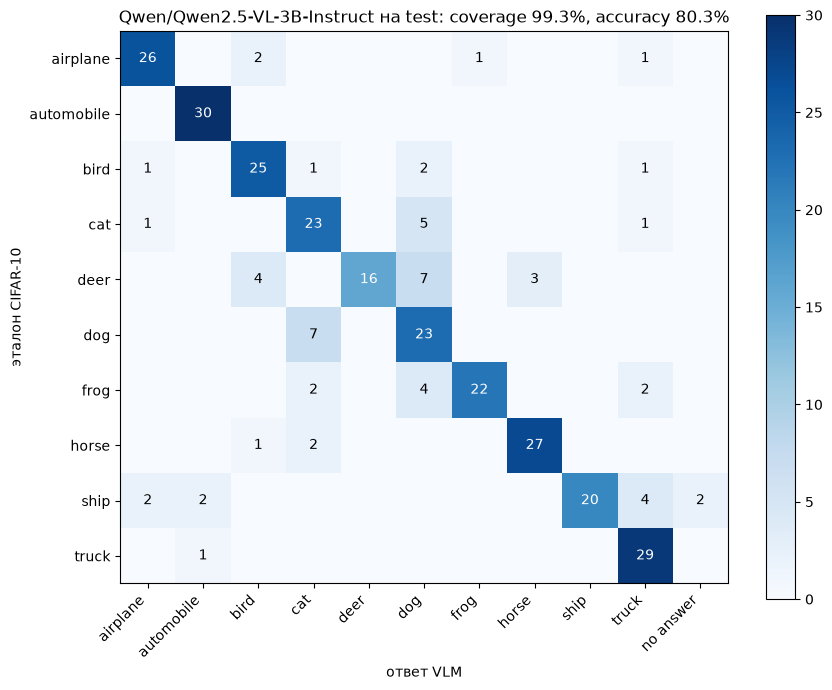

{'n_test': 300, 'n_valid': 298, 'coverage': 0.9933, 'accuracy_all': 0.8033, 'accuracy_covered': 0.8087, 'macro_precision': 0.8395, 'macro_recall': 0.8033, 'macro_f1': 0.806, 'cohen_kappa_covered': 0.7874}
по классам: {'airplane': (0.8667, 0.8667), 'automobile': (0.9091, 1.0), 'bird': (0.7812, 0.8333), 'cat': (0.6571, 0.7667), 'deer': (1.0, 0.5333), 'dog': (0.561, 0.7667), 'frog': (0.9565, 0.7333), 'horse': (0.9, 0.9), 'ship': (1.0, 0.6667), 'truck': (0.7632, 0.9667)}
частые путаницы: [{'true': 'dog', 'pred': 'cat', 'count': 7}, {'true': 'deer', 'pred': 'dog', 'count': 7}, {'true': 'cat', 'pred': 'dog', 'count': 5}, {'true': 'ship', 'pred': 'truck', 'count': 4}, {'true': 'frog', 'pred': 'dog', 'count': 4}]
по флагу uncertain: {'false': {'n': 297, 'accuracy': 0.8114}, 'true': {'n': 1, 'accuracy': 0.0}}


In [8]:
# Задание 7. Покрытие и матрица ошибок
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, precision_recall_fscore_support
import matplotlib.pyplot as plt

# Только настоящие ответы модели: читаем сохранённый annotations.jsonl, а не переменные в памяти
assert ANNOTATIONS_PATH.exists(), "нет annotations.jsonl — сначала выполните задание 5 на GPU"
ann = {r["id"]: r for r in map(json.loads, ANNOTATIONS_PATH.read_text(encoding="utf-8").splitlines())}
test_manifest = [m for m in manifest if m["split"] == "test"]
missing = [m["id"] for m in test_manifest if m["id"] not in ann]
assert not missing, f"разметка test не завершена: нет {len(missing)} изображений (например {missing[:3]})"

NO_ANSWER = "<no_valid_answer>"  # ответ так и не прошёл схему за MAX_ATTEMPTS попыток
y_true = [m["label"] for m in test_manifest]  # эталон берётся из манифеста только здесь, при оценке
y_pred = [ann[m["id"]]["parsed"]["class_name"] if ann[m["id"]]["status"] == "ok" else NO_ANSWER
          for m in test_manifest]
uncertain = [ann[m["id"]]["parsed"]["uncertain"] if ann[m["id"]]["status"] == "ok" else None
             for m in test_manifest]
covered = [p != NO_ANSWER for p in y_pred]

# 1. Coverage — доля test-изображений, для которых получен валидный по схеме ответ
coverage = float(np.mean(covered))

# 2. Precision/recall по классам. Неответ считается ошибкой: он снижает recall своего класса,
#    но не попадает ни в чей precision (NO_ANSWER не входит в labels)
prec, rec, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=CLASSES, zero_division=0)
per_class = {c: {"precision": round(float(p), 4), "recall": round(float(r), 4), "f1": round(float(f), 4),
                 "support": int(s)} for c, p, r, f, s in zip(CLASSES, prec, rec, f1, support)}

# 3. Матрица ошибок: строки — эталон, столбцы — ответ VLM (+ столбец «нет валидного ответа»)
cm_labels = CLASSES + [NO_ANSWER]
cm = confusion_matrix(y_true, y_pred, labels=cm_labels)[:len(CLASSES)]

# Сводные метрики: на всём test (неответ = ошибка) и только на покрытой части
yt_cov = [t for t, c in zip(y_true, covered) if c]
yp_cov = [p for p, c in zip(y_pred, covered) if c]
# Флаг uncertain как прокси уверенности: точность отдельно для «уверенных» и «неуверенных» ответов
unc_groups = {}
for flag in (False, True):
    idx = [i for i, u in enumerate(uncertain) if u is flag]
    unc_groups[str(flag).lower()] = {"n": len(idx),
                                     "accuracy": round(accuracy_score([y_true[i] for i in idx], [y_pred[i] for i in idx]), 4) if idx else None}

# Топ путаниц (эталон -> ответ) и список ошибок для разбора по сохранённым ответам
confusions = sorted(((int(cm[i, j]), CLASSES[i], cm_labels[j]) for i in range(len(CLASSES))
                     for j in range(len(cm_labels)) if i != j and cm[i, j] > 0), reverse=True)
errors = [{"id": m["id"], "true": t, "pred": p, "uncertain": u,
           "caption": ann[m["id"]]["parsed"]["caption"] if ann[m["id"]]["parsed"] else None,
           "raw_last": ann[m["id"]]["attempts"][-1]["raw"]}
          for m, t, p, u in zip(test_manifest, y_true, y_pred, uncertain) if t != p]

test_ann = [ann[m["id"]] for m in test_manifest]
quality = {
    "source": str(ANNOTATIONS_PATH), "split": "test", "model_id": test_ann[0]["model_id"],
    "n_test": len(test_manifest), "n_valid": int(sum(covered)), "coverage": round(coverage, 4),
    "accuracy_all": round(accuracy_score(y_true, y_pred), 4),        # неответ = ошибка
    "accuracy_covered": round(accuracy_score(yt_cov, yp_cov), 4),    # только валидные ответы
    "macro_precision": round(float(np.mean(prec)), 4), "macro_recall": round(float(np.mean(rec)), 4),
    "macro_f1": round(float(np.mean(f1)), 4),
    "cohen_kappa_covered": round(float(cohen_kappa_score(yt_cov, yp_cov, labels=CLASSES)), 4),
    "per_class": per_class,
    "confusion_matrix": {"rows_true": CLASSES, "cols_pred": cm_labels, "matrix": cm.tolist()},
    "top_confusions": [{"true": t, "pred": p, "count": n} for n, t, p in confusions[:10]],
    "by_uncertain_flag": unc_groups,
    "attempts_hist": {str(k): sum(r["n_attempts"] == k for r in test_ann) for k in range(1, MAX_ATTEMPTS + 1)},
    "n_errors": len(errors), "errors": errors,
}
save_json("quality.json", quality)

# Визуализация матрицы ошибок
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(cm_labels)), [c if c != NO_ANSWER else "no answer" for c in cm_labels], rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("ответ VLM"); ax.set_ylabel("эталон CIFAR-10")
ax.set_title(f"{quality['model_id']} на test: coverage {coverage:.1%}, accuracy {quality['accuracy_all']:.1%}")
fig.colorbar(im, ax=ax); fig.tight_layout()
fig.savefig(ARTIFACTS / "confusion_matrix.png", dpi=120); plt.show()

print({k: quality[k] for k in ["n_test", "n_valid", "coverage", "accuracy_all", "accuracy_covered",
                               "macro_precision", "macro_recall", "macro_f1", "cohen_kappa_covered"]})
print("по классам:", {c: (v["precision"], v["recall"]) for c, v in per_class.items()})
print("частые путаницы:", quality["top_confusions"][:5])
print("по флагу uncertain:", unc_groups)


| Метрика | Значение | Что значит |
|---|---|---|
| `n_test` / `n_valid` | 300 / 298 | На 298 картинок модель дала корректный ответ (прошел проверку parse), 2 не прошли проверку |
| `coverage` | 99,33% | Доля картинок с корректным ответом |
| `accuracy_all` | 80,33% | Точность по всем 300, невалидные считаются ошибками |
| `accuracy_covered` | 80,87% | Точность только по 298 корректным ответам |
| `macro_precision` | 83,95% | Средняя по классам доля верных среди ответов «это класс X»/ Precision одного класса. Берём все случаи, когда модель сказала «это dog», и смотрим, сколько из них действительно собаки. Потом берут среднее по всем 10 классам |
| `macro_recall` | 80,33% | Средняя по классам доля найденных объектов класса. Берём все настоящие картинки класса и смотрим, сколько из них модель узнала |
| `macro_f1` | 0,806 | Баланс precision и recall, усреднённый по классам |
| `cohen_kappa_covered` | 0,787 | Согласие с эталоном с поправкой на случайность: 0 — случайно, 1 — идеально. Насколько ответы модели совпадают с настоящими метками с поправкой на случайные совпадения. |

### Задание 8. Экспертная оценка описаний

*Вес: 1 балл.*

**Постановка.** Этап «экспертная оценка описаний» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Соберите отдельные экспертные оценки подписей и не подменяйте их пустым файлом.
2. Сохраните и предъявите artifacts/human_audit.jsonl с экспертными записями.

**Результат.** artifacts/human_audit.jsonl с экспертными записями.

**Критерий принятия.** Задание считается принятым, если artifacts/human_audit.jsonl с экспертными записями получены из фактических входов этого этапа и доступны для проверки.

**Экспертная оценка описаний**

- **Что делали**: вслепую, без показа метки CIFAR, оценили подписи Qwen на 30 test-картинках (по 3 на класс) в форме ipywidgets. Для каждой отметили правильность подписи, типы ошибок, число утверждений и сколько из них не подтверждено, а также верен ли класс.
- **Зачем**: accuracy проверяет только класс, а здесь проверяется, не выдумывает ли модель детали в `caption`.
- **Результат**: human_audit.jsonl и audit_summary.json.
  - Подписи: 17 верных, 9 частично верных, 4 неверных; галлюцинации в 4 из 30.
  - Доля неподтверждённых утверждений H = 18/99 ≈ 0.18.
  - Класс VLM: 25 верно, 4 неверно, 1 неясно. Эксперт совпал с CIFAR в 96.6% случаев, единственное расхождение — test_04906 (CIFAR dog, эксперт и VLM — cat).

In [14]:
# Задание 8. Экспертная оценка описаний (форма в стиле лабораторной №6)
# Оценки ставит человек в форме ниже. Эталон CIFAR-10 эксперту НЕ показывается (слепой аудит);
# он подключается только в сводке, чтобы отделить ошибки VLM от неоднозначных изображений.
import io
from datetime import datetime, timezone
import ipywidgets as W
from IPython.display import display

AUDIT_PATH = ARTIFACTS / "human_audit.jsonl"
AUDIT_SUMMARY_PATH = ARTIFACTS / "audit_summary.json"
AUDIT_PER_CLASS = 3  # 3 изображения на класс по эталону -> 30 изображений из test

# 1. Схема экспертной оценки: качество подписи, типология ошибок, утверждения, вердикт по классу
CORRECTNESS_VALUES = ["correct", "partially_correct", "incorrect"]
ERROR_TYPES = {
    "hallucination": "в подписи есть то, чего нет на изображении",
    "wrong_object": "главный объект назван неверно",
    "attribute": "неверный цвет/размер/вид/порода объекта",
    "spatial": "ошибка в расположении или действии (стоит/летит, слева/справа)",
    "counting": "неверное число объектов",
    "too_vague": "подпись слишком общая, ничего не говорит об изображении",
}
CLASS_VERDICTS = ["correct", "incorrect", "unclear"]  # верен ли class_name VLM по изображению

def empty_review():
    return {"correctness": None, "errors": {t: None for t in ERROR_TYPES},
            "n_claims": None,              # число проверяемых утверждений в подписи
            "n_unsupported_claims": None,  # из них не подтверждены изображением -> H = n_unsupported / n_claims
            "class_verdict": None, "expert_class": None, "comment": "", "reviewer": None, "reviewed_at": None}

def is_reviewed(row):
    return row.get("correctness") is not None and row.get("class_verdict") is not None

def read_audit():
    return [json.loads(l) for l in AUDIT_PATH.read_text(encoding="utf-8").splitlines() if l.strip()] if AUDIT_PATH.exists() else []

def write_audit(rows):
    tmp = AUDIT_PATH.with_suffix(".jsonl.tmp")  # атомарная запись: при сбое старая разметка не теряется
    tmp.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in rows), encoding="utf-8")
    os.replace(tmp, AUDIT_PATH)

def from_legacy(r):
    """Перенос оценок, поставленных через input() (caption_score 2/1/0), в схему формы."""
    return {"correctness": {2: "correct", 1: "partially_correct", 0: "incorrect"}[r["caption_score"]],
            "errors": {t: False for t in ERROR_TYPES}, "n_claims": None, "n_unsupported_claims": None,
            "class_verdict": {True: "correct", False: "incorrect", None: "unclear"}[r["class_ok"]],
            "expert_class": r["expert_class"], "comment": r.get("comment", ""),
            "reviewer": r.get("expert_id"), "reviewed_at": r.get("timestamp")}

# 2. Выборка для аудита: стратифицирована по эталону, фиксирована seed, только валидные ответы VLM на test
rng = np.random.default_rng(SEED + 7)
audit_ids = []
for cls in CLASSES:
    ids = [m["id"] for m in test_manifest if m["label"] == cls and ann[m["id"]]["status"] == "ok"]
    audit_ids += sorted(rng.choice(ids, min(AUDIT_PER_CLASS, len(ids)), replace=False).tolist())
rng.shuffle(audit_ids)  # порядок показа перемешан, чтобы классы не шли подряд

# 3. Заготовка: строка на каждое изображение выборки. Уже заполненные оценки не перезаписываются
existing = {r["id"]: r for r in read_audit()}
rows = []
for i in audit_ids:
    old = existing.get(i, {})
    if "correctness" in old:
        rows.append(old); continue
    a = ann[i]["parsed"]
    rows.append({"id": i, "path": ann[i]["path"], "vlm_class": a["class_name"], "uncertain": a["uncertain"],
                 "caption": a["caption"], "raw_output": ann[i]["attempts"][-1]["raw"], "model_id": ann[i]["model_id"],
                 **(from_legacy(old) if "caption_score" in old else empty_review())})
write_audit(rows)

def build_audit_summary():
    """Сводка только по реально просмотренным строкам; пока есть ожидающие — помечена как предварительная."""
    rows = read_audit()
    done = [r for r in rows if is_reviewed(r)]
    pending = [r["id"] for r in rows if not is_reviewed(r)]
    is_final = bool(done) and not pending
    label_of = {m["id"]: m["label"] for m in test_manifest}  # эталон — только здесь
    with_claims = [r for r in done if r.get("n_claims")]
    n_claims = sum(r["n_claims"] for r in with_claims)
    n_unsup = sum(r["n_unsupported_claims"] or 0 for r in with_claims)
    with_cls = [r for r in done if r["expert_class"]]
    n = len(done)
    summary = {
        "status": "final" if is_final else "preliminary",
        "note": ("все строки просмотрены — частоты итоговые" if is_final else
                 f"ПРЕДВАРИТЕЛЬНЫЙ отчёт: просмотрено {n} из {len(rows)}; частоты не являются итоговыми"),
        "model_id": rows[0]["model_id"], "blind_to_cifar_label": True, "per_class_sample": AUDIT_PER_CLASS,
        "reviewers": sorted({r["reviewer"] for r in done if r["reviewer"]}),
        "n_total": len(rows), "n_reviewed": n, "n_pending": len(pending), "pending_ids": pending,
        "caption_correctness": {c: sum(r["correctness"] == c for r in done) for c in CORRECTNESS_VALUES},
        "error_counts": {t: sum(bool(r["errors"].get(t)) for r in done) for t in ERROR_TYPES},
        "error_rates": {t: round(sum(bool(r["errors"].get(t)) for r in done) / n, 4) if n else None for t in ERROR_TYPES},
        "hallucination_rate_claims": {"H": round(n_unsup / n_claims, 4) if n_claims else None,
                                      "n_unsupported_claims": n_unsup, "n_claims": n_claims,
                                      "n_examples_with_claims": len(with_claims),
                                      "definition": "H = N_unsupported / N_claims по просмотренным примерам"},
        "class_verdicts": {v: sum(r["class_verdict"] == v for r in done) for v in CLASS_VERDICTS},
        "vlm_vs_cifar_accuracy_on_reviewed": round(float(np.mean([r["vlm_class"] == label_of[r["id"]] for r in done])), 4) if n else None,
        "expert_vs_cifar_agreement": round(float(np.mean([r["expert_class"] == label_of[r["id"]] for r in with_cls])), 4) if with_cls else None,
        "expert_vs_cifar_disagreements": [{"id": r["id"], "expert": r["expert_class"], "cifar": label_of[r["id"]],
                                           "vlm": r["vlm_class"]} for r in with_cls if r["expert_class"] != label_of[r["id"]]],
        "error_type_definitions": ERROR_TYPES,
        "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }
    save_json(AUDIT_SUMMARY_PATH.name, summary)
    return summary

def image_png(path, side=256):
    buf = io.BytesIO()
    Image.open(path).convert("RGB").resize((side, side), Image.BICUBIC).save(buf, format="PNG")
    return buf.getvalue()

# 4. Форма экспертной разметки: изображение + ответ VLM -> ручные поля
def audit_form():
    rows0 = read_audit()
    ids = [r["id"] for r in rows0]
    state = {"i": next((k for k, r in enumerate(rows0) if not is_reviewed(r)), 0)}  # с первой неоценённой
    img = W.Image(format="png", layout=W.Layout(width="256px", height="256px"))
    info = W.HTML(layout=W.Layout(width="100%"))
    correctness = W.ToggleButtons(options=[("— не оценено —", None)] + [(c, c) for c in CORRECTNESS_VALUES],
                                  description="подпись")
    err_boxes = {t: W.Checkbox(description=t, tooltip=d, indent=False, layout=W.Layout(width="130px"))
                 for t, d in ERROR_TYPES.items()}
    n_claims = W.BoundedIntText(min=0, max=20, description="утверждений", layout=W.Layout(width="200px"))
    n_unsup = W.BoundedIntText(min=0, max=20, description="неподтв.", layout=W.Layout(width="200px"))
    class_verdict = W.ToggleButtons(options=[("— не оценено —", None)] + [(v, v) for v in CLASS_VERDICTS],
                                    description="класс VLM")
    expert_class = W.Dropdown(options=[("—", None)] + [(c, c) for c in CLASSES], description="класс эксперта")
    comment = W.Textarea(placeholder="что именно не так (по изображению)", layout=W.Layout(width="95%", height="50px"))
    reviewer = W.Text(description="эксперт", value=os.getenv("CV_EXPERT_ID", ""), layout=W.Layout(width="300px"))
    status = W.HTML()
    b_prev, b_next = W.Button(description="◀ назад"), W.Button(description="вперёд ▶")
    b_save = W.Button(description="Сохранить", button_style="success", icon="check")
    b_pending = W.Button(description="к следующей неоценённой", icon="forward")

    def esc(s):
        return str(s).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")

    def show():
        rows = {r["id"]: r for r in read_audit()}
        r = rows[ids[state["i"]]]
        img.value = image_png(r["path"])
        info.value = (f"<b>{state['i'] + 1}/{len(ids)} · {r['id']}</b><br>"
                      f"<b>Класс VLM:</b> {esc(r['vlm_class'])} (uncertain={r['uncertain']})<br>"
                      f"<b>Подпись VLM:</b> {esc(r['caption'])}<br>"
                      f"<b>Сырой ответ:</b><pre style='white-space:pre-wrap'>{esc(r['raw_output'])}</pre>")
        correctness.value = r["correctness"]
        for t, cb in err_boxes.items():
            cb.value = bool(r["errors"].get(t))
        n_claims.value = r["n_claims"] or 0
        n_unsup.value = r["n_unsupported_claims"] or 0
        class_verdict.value = r["class_verdict"]
        expert_class.value = r["expert_class"]
        comment.value = r["comment"] or ""
        reviewer.value = r["reviewer"] or reviewer.value
        n_done = sum(is_reviewed(x) for x in rows.values())
        status.value = (f"Строка: <b>{'оценена' if is_reviewed(r) else 'ожидает оценки'}</b> · "
                        f"всего оценено {n_done}/{len(rows)}, ожидают {len(rows) - n_done}")

    def on_save(_):
        if correctness.value is None or class_verdict.value is None:
            status.value = "<span style='color:#c00'>Заполните оценку подписи и вердикт по классу</span>"; return
        if n_unsup.value > n_claims.value:
            status.value = "<span style='color:#c00'>Неподтверждённых утверждений больше, чем всех</span>"; return
        if not reviewer.value.strip():
            status.value = "<span style='color:#c00'>Укажите эксперта</span>"; return
        rows = read_audit()
        r = next(x for x in rows if x["id"] == ids[state["i"]])
        r.update(correctness=correctness.value, errors={t: cb.value for t, cb in err_boxes.items()},
                 n_claims=n_claims.value or None, n_unsupported_claims=n_unsup.value if n_claims.value else None,
                 class_verdict=class_verdict.value,
                 # при верном классе VLM класс эксперта совпадает с ним; при unclear — не определён
                 expert_class=(r["vlm_class"] if class_verdict.value == "correct" else
                               expert_class.value if class_verdict.value == "incorrect" else None),
                 comment=comment.value, reviewer=reviewer.value.strip(),
                 reviewed_at=datetime.now(timezone.utc).isoformat(timespec="seconds"))
        write_audit(rows)
        rep = build_audit_summary()
        to_pending(None)
        status.value += f" · сохранено, audit_summary.json обновлён ({rep['status']})"

    def move(step):
        state["i"] = (state["i"] + step) % len(ids); show()

    def to_pending(_):
        rows = {r["id"]: r for r in read_audit()}
        for k in range(1, len(ids) + 1):
            j = (state["i"] + k) % len(ids)
            if not is_reviewed(rows[ids[j]]):
                state["i"] = j; show(); return
        show(); status.value += " · все строки оценены"

    b_prev.on_click(lambda _: move(-1)); b_next.on_click(lambda _: move(1))
    b_save.on_click(on_save); b_pending.on_click(to_pending)
    show()
    return W.VBox([W.HBox([img, info]), correctness, W.HBox(list(err_boxes.values())),
                   W.HBox([n_claims, n_unsup]), W.HBox([class_verdict, expert_class]),
                   W.HBox([reviewer]), comment, W.HBox([b_prev, b_next, b_pending, b_save]), status])

display(audit_form())

# 5. Сколько заполнено и сколько ожидает; без завершения частоты не выдаются за итоговые
report = build_audit_summary()
print(f"Просмотрено {report['n_reviewed']} из {report['n_total']}, ожидают оценки {report['n_pending']}")
print(f"Статус: {report['status']} — {report['note']}")
print("Чтобы обновить сводку после заполнения формы: build_audit_summary()")


Просмотрено 30 из 30, ожидают оценки 0
Статус: final — все строки просмотрены — частоты итоговые
Чтобы обновить сводку после заполнения формы: build_audit_summary()


### Задание 9. Визуальные признаки для downstream

*Вес: 1 балл.*

**Постановка.** Этап «визуальные признаки для downstream» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Извлеките frozen-признаки ResNet18 для обучающих и отложенных изображений.
2. Сохраните и предъявите признаки ResNet18 train/test.

**Результат.** признаки ResNet18 train/test.

**Критерий принятия.** Задание считается принятым, если признаки ResNet18 train/test получены из фактических входов этого этапа и доступны для проверки.

**Визуальные признаки для downstream**

- **Что делали**: взяли ResNet18 с весами ImageNet, заменили последний слой (он выдавал оценки на 1 000 классов) на Identity (сейчас она возвращае 512 признаков) и заморозили. Картинки увеличили до 224×224 (bicubic) и нормировали, затем получили по вектору из 512 чисел для 500 train- и 300 test-картинок. Сеть не обучали, признаки кэшируются.
- **Зачем**: дать обоим классификаторам задания 10 одинаковый вход, чтобы разница между ними зависела только от меток.
- **Результат**: resnet18_features.npz и features_meta.json. Матрицы 500×512 и 300×512, статистики train и test близки (среднее 0.745 в обеих частях).

In [10]:
# Задание 9. Визуальные признаки для downstream
import torchvision
from torchvision import transforms as T
from torch.utils.data import DataLoader, Dataset

FEATURES_PATH = ARTIFACTS / "resnet18_features.npz"

# 1. Frozen ResNet18 с весами ImageNet: классификационная голова заменена на Identity -> 512-мерный вектор
weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
backbone = torchvision.models.resnet18(weights=weights)
backbone.fc = torch.nn.Identity()
backbone = backbone.to(DEVICE).eval()
for p in backbone.parameters():
    p.requires_grad_(False)  # признаки извлекаются, сеть не обучается

# CIFAR 32x32 растягиваем до 224x224 целиком (без center crop, чтобы не срезать края) и нормализуем как ImageNet
mean, std = weights.transforms().mean, weights.transforms().std
feat_tf = T.Compose([T.Resize((224, 224), interpolation=T.InterpolationMode.BICUBIC), T.ToTensor(), T.Normalize(mean, std)])

class ManifestImages(Dataset):
    """Те же PNG из манифеста, что видела VLM; метки здесь не используются."""
    def __init__(self, records):
        self.records = records
    def __len__(self):
        return len(self.records)
    def __getitem__(self, i):
        return feat_tf(Image.open(self.records[i]["path"]).convert("RGB"))

@torch.no_grad()
def extract(records, batch_size=128):
    loader = DataLoader(ManifestImages(records), batch_size=batch_size, shuffle=False, num_workers=0)
    return np.concatenate([backbone(x.to(DEVICE)).float().cpu().numpy() for x in loader]).astype(np.float32)

# 2. Признаки train/test. Кэш переиспользуется, только если ID совпадают с текущим манифестом
splits = {s: [m for m in manifest if m["split"] == s] for s in ("train", "test")}
cached = np.load(FEATURES_PATH, allow_pickle=False) if FEATURES_PATH.exists() else None
if cached is not None and all(np.array_equal(cached[f"{s}_ids"], [m["id"] for m in splits[s]]) for s in splits):
    features = {s: cached[f"{s}_X"] for s in splits}
    print("признаки загружены из кэша:", FEATURES_PATH)
else:
    t0 = time.perf_counter()
    features = {s: extract(recs) for s, recs in splits.items()}
    np.savez(FEATURES_PATH, **{f"{s}_X": features[s] for s in splits},
             **{f"{s}_ids": np.array([m["id"] for m in splits[s]]) for s in splits})
    print(f"признаки извлечены за {time.perf_counter() - t0:.1f} с -> {FEATURES_PATH}")

# Проверки: размерность 512, число строк = число изображений, нет NaN, train/test не пересекаются по ID
for s, recs in splits.items():
    assert features[s].shape == (len(recs), 512), f"{s}: форма {features[s].shape}"
    assert np.isfinite(features[s]).all(), f"{s}: NaN/inf в признаках"
assert not {m["id"] for m in splits["train"]} & {m["id"] for m in splits["test"]}

features_meta = {
    "backbone": "torchvision resnet18", "weights": str(weights), "frozen": True, "head": "fc -> Identity",
    "transform": "Resize(224x224, bicubic) + ImageNet normalize", "dim": 512, "file": str(FEATURES_PATH),
    "n": {s: len(recs) for s, recs in splits.items()},
    "feature_stats": {s: {"mean": round(float(features[s].mean()), 4), "std": round(float(features[s].std()), 4)}
                      for s in splits},
}
save_json("features_meta.json", features_meta)
print(json.dumps(features_meta, ensure_ascii=False, indent=2))


признаки загружены из кэша: artifacts\lab7\resnet18_features.npz
{
  "backbone": "torchvision resnet18",
  "weights": "ResNet18_Weights.IMAGENET1K_V1",
  "frozen": true,
  "head": "fc -> Identity",
  "transform": "Resize(224x224, bicubic) + ImageNet normalize",
  "dim": 512,
  "file": "artifacts\\lab7\\resnet18_features.npz",
  "n": {
    "train": 500,
    "test": 300
  },
  "feature_stats": {
    "train": {
      "mean": 0.7453,
      "std": 0.9131
    },
    "test": {
      "mean": 0.7454,
      "std": 0.9205
    }
  }
}


Что было сделано:
1. Загрузили ResNet18 с весами ImageNet.
2. Убрали последний слой, который выдаёт классы ImageNet.
3. Пропустили через сеть все 800 картинок.
4. Для каждой картинки получили вектор из 512 чисел. Это её числовое описание: формы, текстуры, цвета.


### Задание 10. Классификаторы при равном бюджете

*Вес: 1 балл.*

**Постановка.** Этап «классификаторы при равном бюджете» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Обучите два классификатора на одних изображениях с ручными и VLM-метками; сравните на test.
2. Сохраните и предъявите artifacts/downstream.json и подтверждённый аудит.

**Результат.** artifacts/downstream.json и подтверждённый аудит.

**Критерий принятия.** Задание считается принятым, если artifacts/downstream.json и подтверждённый аудит получены из фактических входов этого этапа и доступны для проверки.

Два классификатора устроены одинаково StandardScaler + логистическая регрессия на 512 признаках ResNet18. Обучались они на одних и тех же 497 картинках train: 3 из 500 исключены, потому что на них Qwen не дала корректного ответа.<br>Каждый классификатор получал разные метки

Схема
```
train-картинки → ResNet18 → векторы ─┬─ ручные метки → классификатор 1 ─┐
                                     └─ метки Qwen  → классификатор 2 ─┤
                                                                       ↓
                        300 test-картинок → ответы сравниваются с эталоном
```



**Классификаторы при равном бюджете**

- **Что делали**: обучили два одинаковых классификатора (StandardScaler + логистическая регрессия, C подбирали 5-fold CV на train) на одних и тех же 497 train-картинках. Один обучали на ручных метках (классификатор 1: векторы + ручные метки), другой — на метках Qwen (классификатор 2: векторы + метки Qwen); 3 картинки без ответа VLM исключили из обоих. Оба проверили на 300 test-картинках по эталону CIFAR-10.
- **Зачем**: узнать, сколько качества теряется, если заменить ручную разметку автоматической.
- **Результат**: downstream.json.
  - Ручные метки — 86.0% на test, метки Qwen — 79.7%.
  - Разница −6.3 п.п., 95% (доверительный интервал) bootstrap (получен методом бутстрепа) CI [−11; −2], то есть потеря значима.
  - Шум меток (ошибочные метки) Qwen на train — 18.1%.

In [11]:
# Задание 10. Классификаторы при равном бюджете
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, recall_score

DOWNSTREAM_PATH = ARTIFACTS / "downstream.json"

# 0. Подтверждённый аудит: без завершённой экспертной проверки сравнение не принимается
audit_saved = json.loads((ARTIFACTS / "audit_summary.json").read_text(encoding="utf-8"))
audit_rows = [json.loads(l) for l in (ARTIFACTS / "human_audit.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()]
assert audit_saved["status"] == "final" and audit_saved["n_pending"] == 0, "аудит не завершён — закончите задание 8"
assert all(r["correctness"] and r["class_verdict"] and r["reviewer"] for r in audit_rows), "в human_audit.jsonl есть пустые записи"

# 1. Данные с диска: признаки (задание 9), эталон (манифест), VLM-метки (annotations.jsonl)
feats = np.load(ARTIFACTS / "resnet18_features.npz", allow_pickle=False)
gold = {m["id"]: m["label"] for m in manifest}
vlm = {r["id"]: r["parsed"]["class_name"]
       for r in map(json.loads, ANNOTATIONS_PATH.read_text(encoding="utf-8").splitlines()) if r["status"] == "ok"}

# Равный бюджет: оба классификатора учатся на ОДНИХ И ТЕХ ЖЕ train-изображениях — тех, где у VLM есть
# валидный ответ. Изображения без VLM-метки исключаются из обоих вариантов, иначе у «ручного» было бы больше данных
train_ids = feats["train_ids"].tolist()
keep = np.array([i in vlm for i in train_ids])
X_train, ids_train = feats["train_X"][keep], [i for i, k in zip(train_ids, keep) if k]
y_train = {"manual": np.array([gold[i] for i in ids_train]),  # ручные (эталонные) метки CIFAR-10
           "vlm": np.array([vlm[i] for i in ids_train])}      # метки Qwen2.5-VL
X_test, ids_test = feats["test_X"], feats["test_ids"].tolist()
y_test = np.array([gold[i] for i in ids_test])                # оценка обоих — только по эталону на test

noise = float(np.mean(y_train["manual"] != y_train["vlm"]))
print(f"train: {len(ids_train)} изображений (исключено без VLM-ответа: {int((~keep).sum())}); "
      f"доля VLM-меток, отличных от эталона: {noise:.1%}; test: {len(ids_test)}")

# 2. Одинаковая процедура для обоих: StandardScaler + логистическая регрессия на frozen-признаках.
#    C подбирается 5-fold CV только на train и только по своим меткам (test в выборе не участвует)
def fit_classifier(y):
    search = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                          {"logisticregression__C": [0.001, 0.01, 0.1, 1.0]},
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="accuracy")
    return search.fit(X_train, y)

models = {name: fit_classifier(y) for name, y in y_train.items()}
preds = {name: m.predict(X_test) for name, m in models.items()}

# 3. Сравнение на test + парный bootstrap разницы accuracy (те же test-изображения для обоих)
rng = np.random.default_rng(SEED)
correct = {n: (p == y_test).astype(float) for n, p in preds.items()}
boot = [float(np.mean(correct["vlm"][idx] - correct["manual"][idx]))
        for idx in (rng.integers(0, len(y_test), len(y_test)) for _ in range(2000))]

results = {}
for name, p in preds.items():
    results[name] = {
        "best_C": models[name].best_params_["logisticregression__C"],
        "cv_accuracy_on_own_labels": round(float(models[name].best_score_), 4),
        "test_accuracy": round(accuracy_score(y_test, p), 4),
        "test_macro_f1": round(f1_score(y_test, p, average="macro"), 4),
        "test_recall_per_class": {c: round(float(r), 4)
                                  for c, r in zip(CLASSES, recall_score(y_test, p, labels=CLASSES, average=None))},
    }
delta = results["vlm"]["test_accuracy"] - results["manual"]["test_accuracy"]

downstream = {
    "setup": {"features": "frozen ResNet18 (ImageNet), 512-d, resnet18_features.npz",
              "classifier": "StandardScaler + LogisticRegression, C по 5-fold CV на train",
              "n_train": len(ids_train), "n_excluded_no_vlm_answer": int((~keep).sum()), "n_test": len(ids_test),
              "train_ids_identical_for_both": True, "test_labels": "эталон CIFAR-10",
              "vlm_label_noise_on_train": round(noise, 4)},
    "manual_labels": results["manual"],
    "vlm_labels": results["vlm"],
    "delta_test_accuracy_vlm_minus_manual": round(delta, 4),
    "delta_bootstrap_95ci": [round(float(np.percentile(boot, 2.5)), 4), round(float(np.percentile(boot, 97.5)), 4)],
    "test_agreement_between_classifiers": round(float(np.mean(preds["manual"] == preds["vlm"])), 4),
    "audit": {k: audit_saved[k] for k in ("status", "reviewers", "n_reviewed", "caption_correctness",
                                         "hallucination_rate_claims", "class_verdicts",
                                         "vlm_vs_cifar_accuracy_on_reviewed", "expert_vs_cifar_agreement")},
}
save_json(DOWNSTREAM_PATH.name, downstream)

print(f"{'метки':<8}{'C':>7}{'CV(свои)':>10}{'test acc':>10}{'macro F1':>10}")
for name in ("manual", "vlm"):
    r = results[name]
    print(f"{name:<8}{r['best_C']:>7}{r['cv_accuracy_on_own_labels']:>10.3f}{r['test_accuracy']:>10.3f}{r['test_macro_f1']:>10.3f}")
print(f"Δ accuracy (VLM − manual) = {delta:+.3f}, 95% bootstrap CI {downstream['delta_bootstrap_95ci']}")
print(f"аудит: {audit_saved['status']}, {audit_saved['n_reviewed']} записей, эксперт(ы) {audit_saved['reviewers']}")


train: 497 изображений (исключено без VLM-ответа: 3); доля VLM-меток, отличных от эталона: 18.1%; test: 300
метки         C  CV(свои)  test acc  macro F1
manual    0.001     0.815     0.860     0.860
vlm        0.01     0.708     0.797     0.801
Δ accuracy (VLM − manual) = -0.063, 95% bootstrap CI [-0.11, -0.02]
аудит: final, 30 записей, эксперт(ы) ['Viktor']


### Задание 11. Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

Гипотеза: если увеличить картинку с 32×32 до 224×224 (бикубический апскейл) перед подачей в Qwen, точность классификации CIFAR-10 вырастет. При размере 32×32 модель получает всего 4 визуальных токена, а при 224×224 — 64. Предположение связано с тем, что часть ошибок вызвана тем, что модель видит слишком мало.

Как проверяли:
- Взяли 200 новых картинок, по 20 на класс: они не входили в основной train и test.
- Каждую разметили дважды: в размере 32×32 и 224×224. Поэтому разметок 400.
- Всё остальное оставили одинаковым: модель, промпт, парсер, батч.
- Правило решения задали заранее: гипотеза подтверждается, если нижняя граница 95% доверительного интервала разницы больше 0.



**Творческое мини-исследование**

- **Что делали**: проверили гипотезу, что увеличение картинки с 32×32 до 224×224 (bicubic) повышает accuracy Qwen. Взяли 200 новых train-картинок вне манифеста (по 20 на класс, seed 142) и разметили каждую в обоих размерах. Модель, prompt и parse остались те же. Правило решения зафиксировали заранее: нижняя граница 95% CI больше 0.
- **Зачем**: проверить, не объясняется ли часть ошибок тем, что при 32×32 модель получает всего 4 визуальных токена (при 224×224 — 64).
- **Результат**: bonus_plan.json, bonus_annotations.jsonl, bonus_result.json и bonus.md.
  - Accuracy выросла с 81.0% до 87.0%, coverage — с 98% до 100%.
  - Разница +6 п.п., 95% CI [0; +12]; 24 картинки верны только при 224, 12 — только при 32 (McNemar p ≈ 0.065).
  - Гипотеза не подтверждена: нижняя граница CI не больше 0.

In [12]:
# Творческое мини-исследование: ограничение по разрешению входа
# Гипотеза выбрана ДО просмотра test, по механике модели и шуму VLM-меток на train (задание 10):
#   CIFAR-10 — 32x32, и Qwen2.5-VL видит такое изображение всего несколькими визуальными токенами.
#   H1: бикубический апскейл до 224x224 перед VLM повышает долю верных классов.
# Проверка — на НОВЫХ реальных изображениях CIFAR-10 (неиспользованная часть train-пула), test не трогаем.
BONUS_PER_CLASS = 20
BONUS_RESOLUTIONS = [32, 224]  # 32 — как в основном эксперименте, 224 — апскейл
BONUS_DIR = LAB_IMAGES / "bonus"
BONUS_ANN_PATH = ARTIFACTS / "bonus_annotations.jsonl"
BONUS_MD_PATH = ARTIFACTS / "bonus.md"
assert VLM_READY, "бонус требует GPU и загруженной VLM (задание 5)"

# 1. Протокол фиксируется до запуска
bonus_plan = {
    "hypothesis": "апскейл 32->224 (bicubic) перед Qwen2.5-VL повышает accuracy классификации CIFAR-10",
    "motivation": [f"шум VLM-меток на train: {json.loads((ARTIFACTS / 'downstream.json').read_text(encoding='utf-8'))['setup']['vlm_label_noise_on_train']:.1%}",
                   "у 32x32 изображения очень мало визуальных токенов (число измеряется ниже)"],
    "data": f"по {BONUS_PER_CLASS} новых изображений на класс из train-пула CIFAR-10, не входящих в манифест; seed {SEED + 100}",
    "conditions": BONUS_RESOLUTIONS, "same": "модель, prompt, parse, retry, batch, greedy — как в задании 5",
    "metric": "accuracy по эталону (без валидного ответа = ошибка); парный bootstrap разницы 224−32, 95% CI",
    "decision_rule": "H1 подтверждена, если нижняя граница CI > 0",
    "fixed_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}
if not (ARTIFACTS / "bonus_plan.json").exists():  # план не перезаписывается при повторных запусках
    save_json("bonus_plan.json", bonus_plan)

# 2. Новые реальные входы: стратифицированно из train_ds, исключая изображения основного эксперимента
used = {m["index"] for m in manifest if m["split"] == "train"}
rng_b = np.random.default_rng(SEED + 100)
targets = np.asarray(train_ds.targets)
bonus_idx = {CLASSES[c]: sorted(rng_b.choice([i for i in np.flatnonzero(targets == c) if i not in used],
                                             BONUS_PER_CLASS, replace=False).tolist()) for c in range(len(CLASSES))}
BONUS_DIR.mkdir(parents=True, exist_ok=True)
bonus_records = []
for cls, idxs in bonus_idx.items():
    for idx in idxs:
        img = train_ds[idx][0]
        for res in BONUS_RESOLUTIONS:
            path = BONUS_DIR / f"bonus_{idx:05d}_{res}.png"
            if not path.exists():
                (img if res == 32 else img.resize((res, res), Image.BICUBIC)).save(path)
            bonus_records.append({"id": f"bonus{res}_{idx:05d}", "split": "bonus", "path": path.as_posix(),
                                  "index": int(idx), "res": res, "label": cls})
assert not {r["index"] for r in bonus_records} & used, "бонусные изображения пересекаются с основным train"

# Число визуальных токенов, которое реально получает модель при каждом разрешении
def n_image_tokens(path):
    img = Image.open(path).convert("RGB")
    text = processor.apply_chat_template([{"role": "user", "content": [{"type": "image", "image": img},
                                          {"type": "text", "text": PROMPT}]}], tokenize=False, add_generation_prompt=True)
    grid = processor(text=[text], images=[img], return_tensors="pt")["image_grid_thw"][0]
    return int(grid.prod()) // processor.image_processor.merge_size ** 2
image_tokens = {res: n_image_tokens(next(r["path"] for r in bonus_records if r["res"] == res)) for res in BONUS_RESOLUTIONS}
print("визуальных токенов на изображение:", image_tokens)

# 3. Разметка той же машинерией, что в задании 5 (батчи, retry, сырые ответы), с возобновлением
done_b = load_done(BONUS_ANN_PATH)
todo_b = [r for r in bonus_records if r["id"] not in done_b]
print(f"бонус: размечено {len(done_b)}, осталось {len(todo_b)} из {len(bonus_records)}")
with open(BONUS_ANN_PATH, "a", encoding="utf-8") as f:
    for res in BONUS_RESOLUTIONS:  # батч из изображений одного разрешения
        part = [r for r in todo_b if r["res"] == res]
        for b in range(0, len(part), BATCH_SIZE):
            for r in annotate_batch(part[b:b + BATCH_SIZE]):
                f.write(json.dumps(r, ensure_ascii=False) + "\n")
            f.flush(); os.fsync(f.fileno())
bonus_ann = load_done(BONUS_ANN_PATH)

# 4. Наблюдения: accuracy, recall по классам, парная разница
gold_b = {r["id"]: r["label"] for r in bonus_records}
def pred_of(i):
    a = bonus_ann[i]
    return a["parsed"]["class_name"] if a["status"] == "ok" else NO_ANSWER
idx_list = sorted({r["index"] for r in bonus_records})
correct_b = {res: np.array([pred_of(f"bonus{res}_{i:05d}") == gold_b[f"bonus{res}_{i:05d}"] for i in idx_list], float)
             for res in BONUS_RESOLUTIONS}
by_res = {}
for res in BONUS_RESOLUTIONS:
    ids = [f"bonus{res}_{i:05d}" for i in idx_list]
    yt, yp = [gold_b[i] for i in ids], [pred_of(i) for i in ids]
    by_res[res] = {"n": len(ids), "visual_tokens": image_tokens[res],
                   "coverage": round(float(np.mean([p != NO_ANSWER for p in yp])), 4),
                   "accuracy": round(float(correct_b[res].mean()), 4),
                   "recall_per_class": {c: round(float(r), 4) for c, r in
                                        zip(CLASSES, recall_score(yt, yp, labels=CLASSES, average=None, zero_division=0))},
                   "pred_share_dog": round(float(np.mean([p == "dog" for p in yp])), 4),
                   "uncertain_rate": round(float(np.mean([bonus_ann[i]["parsed"]["uncertain"] for i in ids
                                                           if bonus_ann[i]["status"] == "ok"])), 4),
                   "mean_seconds": round(float(np.mean([bonus_ann[i]["total_seconds"] for i in ids])), 3)}
diff = correct_b[224] - correct_b[32]
boot_b = [float(diff[rng_b.integers(0, len(diff), len(diff))].mean()) for _ in range(2000)]
ci = [round(float(np.percentile(boot_b, 2.5)), 4), round(float(np.percentile(boot_b, 97.5)), 4)]
only_224, only_32 = int(((correct_b[224] == 1) & (correct_b[32] == 0)).sum()), int(((correct_b[32] == 1) & (correct_b[224] == 0)).sum())
main_test_acc = json.loads((ARTIFACTS / "quality.json").read_text(encoding="utf-8"))["accuracy_all"]
verdict = ("подтверждена" if ci[0] > 0 else
           "опровергнута: апскейл ухудшает" if ci[1] < 0 else "не подтверждена: разница в пределах шума")

bonus_result = {"plan": bonus_plan, "by_resolution": by_res, "delta_accuracy_224_minus_32": round(float(diff.mean()), 4),
                "delta_95ci": ci, "only_224_correct": only_224, "only_32_correct": only_32,
                "main_test_accuracy_32": main_test_acc, "verdict": verdict}
save_json("bonus_result.json", bonus_result)

# 5. Отчёт artifacts/lab7/bonus.md
rec_rows = "\n".join(f"| {c} | {by_res[32]['recall_per_class'][c]:.2f} | {by_res[224]['recall_per_class'][c]:.2f} |" for c in CLASSES)
BONUS_MD_PATH.write_text(f"""# Бонус: ограничение VLM-разметки по разрешению входа

## Гипотеза
{bonus_plan['hypothesis']}.

Мотивация (без использования отложенного test): {'; '.join(bonus_plan['motivation'])}.
При 32x32 модель получает {image_tokens[32]} визуальных токенов, при 224x224 — {image_tokens[224]}.

## Протокол
- Данные: {bonus_plan['data']}; пересечение с основным train/test отсутствует.
- Условия: {BONUS_RESOLUTIONS[0]}x{BONUS_RESOLUTIONS[0]} (как в основном эксперименте) и {BONUS_RESOLUTIONS[1]}x{BONUS_RESOLUTIONS[1]} (bicubic).
- Одинаково: {MODEL_ID}, тот же prompt (sha1 {PROMPT_SHA1[:10]}), parse, до {MAX_ATTEMPTS} попыток, batch {BATCH_SIZE}, greedy.
- Метрика: {bonus_plan['metric']}. Правило решения: {bonus_plan['decision_rule']}.
- Протокол зафиксирован в bonus_plan.json до запуска; сырые ответы — bonus_annotations.jsonl.

## Наблюдения
| | 32x32 | 224x224 |
|---|---|---|
| визуальных токенов | {image_tokens[32]} | {image_tokens[224]} |
| coverage | {by_res[32]['coverage']:.1%} | {by_res[224]['coverage']:.1%} |
| accuracy | {by_res[32]['accuracy']:.1%} | {by_res[224]['accuracy']:.1%} |
| доля ответов «dog» | {by_res[32]['pred_share_dog']:.1%} | {by_res[224]['pred_share_dog']:.1%} |
| доля uncertain=true | {by_res[32]['uncertain_rate']:.1%} | {by_res[224]['uncertain_rate']:.1%} |
| сек/изображение | {by_res[32]['mean_seconds']} | {by_res[224]['mean_seconds']} |

Разница accuracy (224 − 32): {diff.mean():+.1%}, 95% CI [{ci[0]:+.1%}, {ci[1]:+.1%}];
верно только при 224: {only_224}, только при 32: {only_32}.

| класс | recall 32 | recall 224 |
|---|---|---|
{rec_rows}

## Сопоставление с основным экспериментом
Accuracy VLM на основном test (32x32): {main_test_acc:.1%}; на бонусной выборке при 32x32: {by_res[32]['accuracy']:.1%}.
Расхождение {by_res[32]['accuracy'] - main_test_acc:+.1%} объясняется другими изображениями (train-пул вместо test)
и размером выборок (300 и {len(idx_list)}: стандартная ошибка accuracy ~2–3 п.п.).

## Вывод
Гипотеза {verdict} (правило: нижняя граница CI > 0).
Разница accuracy (224 − 32): {diff.mean():+.1%}, 95% bootstrap CI [{ci[0]:+.1%}, {ci[1]:+.1%}]; нижняя граница {'больше' if ci[0] > 0 else 'не превышает'} 0.
""", encoding="utf-8")
print(BONUS_MD_PATH.read_text(encoding="utf-8"))


визуальных токенов на изображение: {32: 4, 224: 64}
бонус: размечено 400, осталось 0 из 400
# Бонус: ограничение VLM-разметки по разрешению входа

## Гипотеза
апскейл 32->224 (bicubic) перед Qwen2.5-VL повышает accuracy классификации CIFAR-10.

Мотивация (без использования отложенного test): шум VLM-меток на train: 18.1%; у 32x32 изображения очень мало визуальных токенов (число измеряется ниже).
При 32x32 модель получает 4 визуальных токенов, при 224x224 — 64.

## Протокол
- Данные: по 20 новых изображений на класс из train-пула CIFAR-10, не входящих в манифест; seed 142; пересечение с основным train/test отсутствует.
- Условия: 32x32 (как в основном эксперименте) и 224x224 (bicubic).
- Одинаково: Qwen/Qwen2.5-VL-3B-Instruct, тот же prompt (sha1 dd128110a6), parse, до 3 попыток, batch 32, greedy.
- Метрика: accuracy по эталону (без валидного ответа = ошибка); парный bootstrap разницы 224−32, 95% CI. Правило решения: H1 подтверждена, если нижняя граница CI > 0.
- Протокол зафиксирован в

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.


**Данные и модель.** CIFAR-10, стратифицированная выборка с seed 42: train 500 (по 50 на класс), test 300 (по 30 на класс). Части не пересекаются ни по ID, ни по путям, ни по sha1 пикселей (`images.jsonl`). Разметчик — Qwen2.5-VL-3B-Instruct в NF4 (bitsandbytes), greedy, `max_new_tokens=96`, батчи по 32 с левым паддингом, prompt sha1 `dd128110`. RTX 3060 12 ГБ: 800 изображений за ≈3,5 мин (0,25 с на изображение), запуск полный (`FAST_DEV_RUN=False`).

**Качество VLM-разметки на test** (`quality.json`, 300 изображений, эталон CIFAR-10):

| Метрика | Значение |
|---|---|
| coverage (валидный ответ по схеме) | 99,3 % (298 / 300) |
| accuracy, без ответа = ошибка | 80,3 % |
| accuracy на покрытых | 80,9 % |
| macro precision / recall / F1 | 0,84 / 0,80 / 0,81 |
| Cohen κ (VLM vs эталон) | 0,79 |

| Класс | airplane | automobile | bird | cat | deer | dog | frog | horse | ship | truck |
|---|---|---|---|---|---|---|---|---|---|---|
| precision | 0,87 | 0,91 | 0,78 | 0,66 | 1,00 | 0,56 | 0,96 | 0,90 | 1,00 | 0,76 |
| recall | 0,87 | 1,00 | 0,83 | 0,77 | 0,53 | 0,77 | 0,73 | 0,90 | 0,67 | 0,97 |

**Разбор ошибок** (59 ошибок на test; список с сырыми ответами — `quality.json → errors`, матрица — `confusion_matrix.png`):
- **Притяжение к «dog».** Модель ответила «dog» 41 раз при 30 настоящих собаках, отсюда precision dog 0,56. Туда уходят олени (deer→dog 7), лягушки (frog→dog 4) и кошки (cat→dog 5). У deer самый низкий recall 0,53: кроме dog, оленей называют bird (4) и horse (3).
- **Пара cat ↔ dog** (dog→cat 7, cat→dog 5). Это ожидаемая трудность при 32×32.
- **Транспорт.** ship→truck 4, →automobile 2, →airplane 2; truck при этом собирает лишнее (precision 0,76).
- **Все 5 невалидных ответов** (2 test, 3 train) — не сбой формата, а **синонимы вне словаря**: «boat» (4 раза) и «tree» (1). Повтор с причиной отказа не помог: модель трижды подряд отвечала «boat». Строгая схема превращает смыслово верный ответ (boat ≈ ship) в отсутствие метки, и у ship это даёт 2 из 10 промахов на test. Отображение синонимов (boat→ship) подняло бы coverage, но это изменение схемы, и его нужно фиксировать до оценки на test.
- **Формат.** На test 296 из 300 ответов прошли схему с первой попытки, ещё 2 — со второй; JSON почти всегда обёрнут в блок ` ```json `, парсер это допускает.
- **Флаг `uncertain` не работает как confidence proxy.** `true` встретился 1 раз из 298, а accuracy «уверенных» ответов 81 %.

**Экспертный аудит** (`human_audit.jsonl`, `audit_summary.json`: 30 изображений test, по 3 на класс, слепой к эталону, статус `final`):
- Подписи: 17 correct / 9 partially_correct / 4 incorrect; доля неподтверждённых утверждений **H = 18 / 99 ≈ 0,18**. Отмеченные типы ошибок: hallucination 4, wrong_object 1, attribute 1, spatial 1. Типичная галлюцинация — перенос цвета или предмета фона на объект и достраивание обстановки (красный ошейник при красном фоне, синее одеяло при коричневом фоне, обочина или тропа, которых нет в кадре).
- Класс VLM по изображению: 25 верно / 4 неверно / 1 неясно. Класс эксперта совпал с эталоном CIFAR в 28 из 29 случаев (96,6 %). Единственное расхождение `test_04906` (эксперт и VLM — cat, CIFAR — dog) показывает, что часть «ошибок» VLM — неоднозначность самих изображений 32×32.
- Подпись и класс оцениваются независимо: при верном классе подпись часто содержит выдуманные детали, поэтому подписи нельзя использовать как метки без проверки.

**Downstream при равном бюджете** (`downstream.json`). Оба классификатора — StandardScaler + LogisticRegression на frozen-признаках ResNet18 — учатся на одних и тех же 497 train-изображениях; 3 без валидного VLM-ответа исключены из обоих. Шум VLM-меток на train — 18,1 %.

| Метки | C (5-fold CV) | CV по своим меткам | test accuracy | test macro F1 |
|---|---|---|---|---|
| ручные (эталон) | 0,001 | 0,815 | **0,860** | 0,860 |
| VLM | 0,01 | 0,708 | **0,797** | 0,801 |

- Потеря от авторазметки — **−6,3 п.п.**, парный bootstrap 95 % CI [−11; −2]: разница значима.
- Классификатор на VLM-метках (79,7 %) почти повторяет точность самого разметчика (80,3 %). Случайные ошибки частично сглаживаются (recall deer 0,53 у VLM → 0,73 у классификатора), систематические наследуются (ship 0,67 → 0,67).
- CV по шумным меткам занижает качество (0,71 против 0,80 на эталонном test): без проверенного вручную подмножества качество модели, обученной на авторазметке, честно не оценить.

**Бонус** (`bonus.md`, 200 новых изображений из неиспользованной части train-пула, test не задействован). Апскейл 32→224 увеличивает число визуальных токенов с 4 до 64 и поднимает accuracy с 81 % до 87 %: Δ +6 п.п., 95 % CI [0; +12], тест Мак-Немара p ≈ 0,065 (24 изображения верны только при 224, 12 — только при 32). По заранее зафиксированному правилу гипотеза не подтверждена, результат пограничный. Accuracy при 32×32 на новой выборке (81 %) согласуется с основным test (80,3 %).

**Ограничения.**
- Test 300 изображений, по 30 на класс: одно изображение меняет recall класса на 3,3 п.п., стандартная ошибка общей accuracy ≈ 2,3 п.п. Выводы по отдельным классам качественные.
- Только CIFAR-10: 32×32 и 10 закрытых классов. На открытую разметку и изображения высокого разрешения выводы не переносятся.
- Аудит выполнил один эксперт на 30 изображениях, межэкспертное согласие не измерено; число утверждений для H подсчитано вручную и приближённо.
- «Ручные» метки — эталон CIFAR-10, который сам содержит неоднозначные изображения (`test_04906`).
- Одна модель, один prompt, greedy. Батчевый инференс с левым паддингом может слегка отличаться от поштучного, это не измерялось.

**Выводы.**
1. Qwen2.5-VL-3B размечает CIFAR-10 zero-shot с accuracy ≈ 80 % и coverage 99 %, за 0,25 с на изображение на RTX 3060. Как предразметка это пригодно, как замена эталона — нет.
2. Ошибки систематические: притяжение к «dog», путаница животных при 32×32, синонимы вне словаря (boat). Систематические ошибки наследует классификатор, обученный на этих метках.
3. При равном бюджете авторазметка стоит 6,3 п.п. downstream-точности (CI [−11; −2]).
4. Самооценка модели (`uncertain`) бесполезна, а проверка на шумных метках занижает качество. Проверенное вручную подмножество обязательно и для оценки, и для поиска систематических ошибок.
5. Подписи содержат галлюцинации примерно в каждом пятом утверждении (H ≈ 0,18) даже при верном классе.


## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.

In [13]:
# Конфигурация запуска, версии зависимостей и перечень артефактов
import hashlib, platform, sys
from importlib import metadata

PACKAGES = ["torch", "torchvision", "transformers", "accelerate", "bitsandbytes", "pillow", "numpy",
            "scikit-learn", "pydantic", "jsonschema", "ipywidgets", "matplotlib"]
versions = {"python": sys.version.split()[0], "platform": platform.platform()}
for p in PACKAGES:
    try:
        versions[p] = metadata.version(p)
    except metadata.PackageNotFoundError:
        versions[p] = None

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

# Резервные копии разметки из промежуточных конфигураций (поштучно, батч 16) в результаты не входят
BACKUPS = {"annotations_single_backup.jsonl", "annotations_batch16_backup.jsonl"}
artifacts_list = {p.name: {"bytes": p.stat().st_size, "sha256": sha256(p)}
                  for p in sorted(ARTIFACTS.iterdir()) if p.is_file() and p.name not in BACKUPS
                  and p.name not in {"run_config.json", "requirements_lab7.txt"}}
images_count = {d.name: len(list(d.glob("*.png"))) for d in sorted(LAB_IMAGES.iterdir()) if d.is_dir()}

run_config = {
    "fast_dev_run": FAST_DEV_RUN, "seed": SEED, "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "data": {"dataset": "CIFAR-10 (torchvision)", "data_root": str(DATA_ROOT),
             "n_per_class": {"train": N_PER_CLASS_TRAIN, "test": N_PER_CLASS_TEST}},
    "vlm": {"model_id": MODEL_ID, "quantization": "bitsandbytes 4-bit nf4, compute fp16", "decoding": "greedy, max_new_tokens=96",
            "batch_size": BATCH_SIZE, "padding_side": "left", "max_attempts": MAX_ATTEMPTS,
            "prompt_sha1": hashlib.sha1(PROMPT.encode("utf-8")).hexdigest()},
    "audit": {"per_class": AUDIT_PER_CLASS, "blind_to_cifar_label": True},
    "downstream": {"features": "frozen ResNet18 IMAGENET1K_V1, 512-d", "classifier": "StandardScaler + LogisticRegression",
                   "C_grid": [0.001, 0.01, 0.1, 1.0], "cv": "StratifiedKFold(5)"},
    "deviations": ["инференс VLM батчами (infer_batch) вместо поштучного infer_image — ради скорости; модель, prompt и декодирование те же",
                   "transformers 5.x вместо 'transformers>=4.51,<5' из комментария VLM_LOADER",
                   "артефакты в artifacts/lab7/ (отдельная папка лабораторной), в т.ч. bonus.md"],
    "versions": versions,
    "artifacts": artifacts_list,
    "images_png": images_count,
}
save_json("run_config.json", run_config)
(ARTIFACTS / "requirements_lab7.txt").write_text(
    "\n".join(f"{p}=={v}" for p, v in versions.items() if p in PACKAGES and v) + "\n", encoding="utf-8")

print(json.dumps({k: run_config[k] for k in ("fast_dev_run", "gpu", "vlm", "versions")}, ensure_ascii=False, indent=2))
print("артефактов:", len(artifacts_list), "| PNG:", images_count)


{
  "fast_dev_run": false,
  "gpu": "NVIDIA GeForce RTX 3060",
  "vlm": {
    "model_id": "Qwen/Qwen2.5-VL-3B-Instruct",
    "quantization": "bitsandbytes 4-bit nf4, compute fp16",
    "decoding": "greedy, max_new_tokens=96",
    "batch_size": 32,
    "padding_side": "left",
    "max_attempts": 3,
    "prompt_sha1": "dd128110a6d5b0f51b8e1f451f031939fd95dc38"
  },
  "versions": {
    "python": "3.12.1",
    "platform": "Windows-11-10.0.22631-SP0",
    "torch": "2.11.0+cu128",
    "torchvision": "0.26.0+cu128",
    "transformers": "5.17.0",
    "accelerate": "1.15.0",
    "bitsandbytes": "0.50.2",
    "pillow": "12.3.0",
    "numpy": "2.5.3",
    "scikit-learn": "1.9.1",
    "pydantic": "2.14.1",
    "jsonschema": "4.26.0",
    "ipywidgets": "8.1.9",
    "matplotlib": "3.11.2"
  }
}
артефактов: 19 | PNG: {'bonus': 400, 'test': 300, 'train': 500}


**Режим.** Все результаты получены в полном режиме (`FAST_DEV_RUN=False`) на RTX 3060 12 ГБ. Фиктивных измерений нет: метрики считаются только по сохранённым ответам модели (`annotations.jsonl`) и ручным записям (`human_audit.jsonl`).

**Конфигурация и версии.** Ячейка выше сохраняет `artifacts/lab7/run_config.json` (seed, размеры выборок, модель, квантование, декодирование, батч, sha1 prompt, параметры аудита и downstream, отклонения от шаблона, sha256 всех артефактов) и `artifacts/lab7/requirements_lab7.txt` с точными версиями пакетов. Основные версии запуска: Python 3.12.1, torch 2.11.0+cu128, torchvision 0.26.0, transformers 5.19.0, accelerate 1.15.0, bitsandbytes 0.50.2, scikit-learn 1.9.1, pydantic 2.14.1.

**Артефакты** (`artifacts/lab7/`):

| Этап | Файлы |
|---|---|
| 1–3. Данные | `dataset.json`, `selection.json`, `images.jsonl`, `images/train`, `images/test` |
| 4. Схема | `schema.json`, `prompt.txt` |
| 5. Разметка | `annotations.jsonl` (сырые ответы, попытки, время), `annotation_summary.json` |
| 6. Smoke | `smoke_check.json` |
| 7. Качество | `quality.json`, `confusion_matrix.png` |
| 8. Аудит | `human_audit.jsonl`, `audit_summary.json` |
| 9. Признаки | `resnet18_features.npz`, `features_meta.json` |
| 10. Downstream | `downstream.json` |
| Бонус | `bonus_plan.json`, `bonus_annotations.jsonl`, `bonus_result.json`, `bonus.md`, `images/bonus` |
| Запуск | `run_config.json`, `requirements_lab7.txt` |

`annotations_single_backup.jsonl` и `annotations_batch16_backup.jsonl` — частичные разметки из промежуточных конфигураций (поштучно, батч 16). В результатах они не используются.

**Повторный запуск.**
1. Окружение: `pip install -r artifacts/lab7/requirements_lab7.txt` (torch с CUDA ставить по инструкции pytorch.org). Нужна GPU с ≥ 6 ГБ памяти. CIFAR-10 берётся из общего каталога `data/` (или скачивается туда).
2. Проверка механики: `FAST_DEV_RUN = True` в первой ячейке → Run All (по 2 изображения на класс, без отчётных метрик).
3. Полный запуск: `FAST_DEV_RUN = False` → ячейки по порядку. Отбор и разбиение детерминированы (seed 42), поэтому выборка совпадёт.
4. Разметка возобновляемая: уже размеченные ID пропускаются. Для чистого повтора удалите `annotations.jsonl` и `bonus_annotations.jsonl`. Размер батча задаётся `CV_VLM_BATCH`; смешивать разметку разных конфигураций код не даёт.
5. Аудит (задание 8): форма продолжает с первой неоценённой строки; `audit_summary.json` становится `final` только после 30/30. Задание 10 без завершённого аудита не выполняется.
6. Модель и путь к артефактам можно переопределить переменными `CV_VLM_MODEL` и `CV_ARTIFACTS`.
